In [2]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python:", sys.version)

for package in (
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "numpy",
    "pandas",
    "matplotlib",
    "otter-grader",
):
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

import torch

print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA build:", torch.version.cuda)

if torch.cuda.is_available():
    for index in range(torch.cuda.device_count()):
        print(f"GPU {index}:", torch.cuda.get_device_name(index))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch: 2.11.0+cu128
transformers: 5.16.1
datasets: 4.8.5
accelerate: 1.14.0
numpy: 2.1.3
pandas: 2.3.3
matplotlib: 3.10.0
otter-grader: NOT INSTALLED
CUDA available: True
PyTorch CUDA build: 12.8
GPU 0: Tesla T4
GPU 1: Tesla T4


In [3]:
!nvidia-smi

Mon Oct 26 23:50:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Environment

| Component | Version / hardware |
|---|---|
| Platform | Kaggle Notebooks |
| GPU used | NVIDIA Tesla T4, GPU 0 |
| GPU memory | 15,360 MiB |
| NVIDIA driver | 580.178.04 |
| Driver-reported CUDA support | 13.0 |
| PyTorch | 2.11.0+cu128 |
| PyTorch CUDA build | 12.8 |
| Transformers | 5.16.1 |
| Python | 3.13.15 |

Two T4 GPUs were available; the experiments used one GPU.

In [6]:
# Initialize Otter
import otter
grader = otter.Notebook("master.ipynb")

# Profiling and Accelerating a Small LLM Workload

A small set of functions you write is autograded on CPU against a tiny model and
a 300-row IMDB sample (fast, offline). The experiments (profiler traces,
compile, mixed precision, sweeps) need a GPU and are graded from your
plots, tables, traces, and written analysis. GPU work is gated behind
`FULL_SCALE = torch.cuda.is_available()` so the notebook runs top to bottom on a
CPU grading container. Do not remove the `FULL_SCALE` gates.

### Tasks
- C1: fine-tune DistilBERT with your own loop.
- C2: per-step timing breakdown with correct CUDA sync.
- C3: input pipeline, num_workers sweep plus pinning and copy overlap.
- C4: profiler trace; classify the step as launch-bound, compute-bound, or input-bound, with evidence.
- C5: find, count, and fix graph breaks.
- C6: torch.compile performance and the compile break-even point.
- C7: mixed precision; step-time and peak-memory change.
- C8: optimizers compared on time, convergence, and memory.

## Setup

Run this cell first. It picks the device, loads the tokenizer from the
bundled `tiny_tokenizer/` folder (the exact same vocabulary as
`distilbert-base-uncased`, so everything you learn here transfers directly),
and sets a few constants used throughout the notebook.

On your GPU machine you can instead do
`AutoTokenizer.from_pretrained("distilbert-base-uncased")` -- it is the same
tokenizer, just fetched fresh from the Hub. We ship a local copy so the
notebook (and the autograder) never depends on network access.

In [7]:
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, DistilBertConfig, DistilBertForSequenceClassification

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FULL_SCALE = torch.cuda.is_available()  # True on your GPU box, False under CPU grading

DATA_DIR = Path("data")
TOKENIZER_DIR = Path("tiny_tokenizer")

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_DIR)

print(f"device: {DEVICE}, FULL_SCALE: {FULL_SCALE}")
print(f"tokenizer vocab_size: {tokenizer.vocab_size}, pad_token_id: {tokenizer.pad_token_id}")

device: cuda, FULL_SCALE: True
tokenizer vocab_size: 30522, pad_token_id: 0


## Data

`data/tiny_imdb.jsonl` is a 300-row sample drawn from the real IMDB training
split (150 positive, 150 negative, `{"text": ..., "label": ...}` per line),
bundled so the notebook and the autograder work fully offline. Use it for
every correctness check below and for quick local iteration.

For the actual graded experiments (C1's full run, C2-C8) you load the real,
full IMDB dataset with `datasets.load_dataset("imdb")` on your GPU machine.
That full-scale loading is inside the `FULL_SCALE` branches further down so
it never runs during CPU grading.

In [8]:
def load_tiny_imdb(path=DATA_DIR / "tiny_imdb.jsonl"):
    rows = []
    with open(path) as f:
        for line in f:
            rows.append(json.loads(line))
    return rows

tiny_rows = load_tiny_imdb()
print(f"tiny_imdb: {len(tiny_rows)} rows, label balance: "
      f"{sum(r['label'] for r in tiny_rows)} positive / "
      f"{sum(1 - r['label'] for r in tiny_rows)} negative")

tiny_imdb: 300 rows, label balance: 150 positive / 150 negative


## The tiny model config used for grading

The functions you write below are tested against a **tiny, randomly
initialized DistilBERT** (2 layers, hidden size 32) built from a
`DistilBertConfig` -- not a full pretrained model. It shares the real
tokenizer's vocabulary (so `vocab_size` and special-token ids match
`distilbert-base-uncased` exactly), which is what makes Q1-Q4 below
meaningful, but it has ~1M parameters instead of ~67M and trains in a
fraction of a second per step. This is the model the hidden tests use; it is
provided, not something you need to write.

In [9]:
def build_tiny_config(num_labels=2, n_layers=2, dim=32, n_heads=4, hidden_dim=64):
    """A tiny DistilBertConfig: same vocabulary as distilbert-base-uncased,
    far fewer layers/dimensions, for fast CPU-only correctness checks."""
    return DistilBertConfig(
        vocab_size=tokenizer.vocab_size,
        max_position_embeddings=128,
        sinusoidal_pos_embds=False,
        n_layers=n_layers,
        n_heads=n_heads,
        dim=dim,
        hidden_dim=hidden_dim,
        dropout=0.1,
        attention_dropout=0.1,
        pad_token_id=tokenizer.pad_token_id,
        num_labels=num_labels,
    )


def build_model(config):
    """Build a DistilBertForSequenceClassification from a config. On your GPU
    run, for the real fine-tuning experiments, you'll instead call
    AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased',
    num_labels=2) to get pretrained weights -- build_model here just wraps
    DistilBertForSequenceClassification(config) so the same call shape works
    for both the tiny and the full-scale model."""
    return DistilBertForSequenceClassification(config)


TINY_CONFIG = build_tiny_config()
tiny_model = build_model(TINY_CONFIG)
print(tiny_model.config)
print(f"tiny model parameter count: {sum(p.numel() for p in tiny_model.parameters()):,}")

DistilBertConfig {
  "activation": "gelu",
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 32,
  "dropout": 0.1,
  "eos_token_id": null,
  "hidden_dim": 64,
  "initializer_range": 0.02,
  "max_position_embeddings": 128,
  "model_type": "distilbert",
  "n_heads": 4,
  "n_layers": 2,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_word_embeddings": true,
  "transformers_version": "5.16.1",
  "vocab_size": 30522
}

tiny model parameter count: 999,074


## C1 (12 pts): Fine-tune a small LLM with your own loop

### Tokenization and dynamic padding

Write `tokenize_function(text, tokenizer, max_len)`: tokenize a single
review's text, **truncating** to at most `max_len` tokens. Do **not** pad
here -- padding to a fixed length up front wastes compute on short reviews.
Instead, `make_collate_fn(tokenizer)` returns a `collate_fn(batch)` that pads
**dynamically**, only up to the longest example in each batch.

In [10]:
def tokenize_function(text, tokenizer, max_len=256):
    """
    Tokenize a single review's text into a list of token ids.
    Truncate to at most `max_len` tokens. Do NOT pad here.

    Args:
        text: a single review string.
        tokenizer: a Hugging Face tokenizer.
        max_len: maximum number of tokens to keep (including special tokens).

    Returns:
        A list[int] of token ids.
    """
    encoded = tokenizer(text,truncation=True,max_length=max_len,padding=False)
    return encoded["input_ids"]

**Your turn.** Implement `make_collate_fn(tokenizer)`. It must return a
function `collate_fn(batch)` where `batch` is a list of dicts
`{"input_ids": List[int], "label": int}`. `collate_fn` should:

- pad every example's `input_ids` to the length of the **longest** example in
  the batch, using `tokenizer.pad_token_id`;
- build a matching `attention_mask` (1 for real tokens, 0 for padding);
- stack `label` into a `LongTensor`.

Return a dict `{"input_ids": LongTensor[B, T], "attention_mask": LongTensor[B, T], "labels": LongTensor[B]}`.

In [11]:
def make_collate_fn(tokenizer):
    pad_id = tokenizer.pad_token_id

    def collate_fn(batch):
        ml = max(len(example["input_ids"]) for example in batch)

        input_ids = []
        attention_masks = []
        labels = []

        for example in batch:
            ids = example["input_ids"]
            padding_length = ml - len(ids)
            input_ids.append(ids + [pad_id] * padding_length)
            attention_masks.append([1] * len(ids) + [0] * padding_length)
            labels.append(example["label"])

        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(attention_masks, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
        }

    return collate_fn


collate_fn = make_collate_fn(tokenizer)
try:
    _demo_batch = [{"input_ids": tokenize_function(r["text"], tokenizer, max_len=64), "label": r["label"]} for r in tiny_rows[:4]]
    _demo_out = collate_fn(_demo_batch)
    print({k: v.shape for k, v in _demo_out.items()})
except Exception as _e:
    print(f"(demo skipped -- implement make_collate_fn above: {type(_e).__name__}: {_e})")

{'input_ids': torch.Size([4, 64]), 'attention_mask': torch.Size([4, 64]), 'labels': torch.Size([4])}


In [12]:
grader.check("q_collate")

q_collate results: All test cases passed!

### The training step

Write `train_one_step(model, batch, optimizer, device)`: move the batch to
`device`, run a forward pass, compute the loss, backpropagate, and take one
optimizer step. Return the scalar loss as a Python `float`.

In [13]:
def train_one_step(model, batch, optimizer, device):
    """
    Run a single training step and return the loss as a Python float.

    Args:
        model: a DistilBertForSequenceClassification.
        batch: a dict with "input_ids", "attention_mask", "labels" tensors
            (as produced by collate_fn), still on CPU.
        optimizer: a torch.optim.Optimizer already built over model.parameters().
        device: the torch.device to run on.

    Steps: zero the gradients, move the batch to `device`, forward pass with
    labels (so the model computes the loss for you), backward pass, optimizer
    step. Return loss.item().
    """
    model.train()
    optimizer.zero_grad(set_to_none=True)
    device_batch = {name: tensor.to(device) for name, tensor in batch.items()}
    outputs = model(**device_batch)
    loss = outputs.loss

    loss.backward()
    optimizer.step()

    return loss.item()

In [14]:
grader.check("q_train_step")

q_train_step results: All test cases passed!

### The full fine-tuning run

On your GPU machine: load the **real** IMDB dataset (`datasets.load_dataset("imdb")`),
tokenize and collate it with the functions above, fine-tune
`distilbert-base-uncased` (`AutoModelForSequenceClassification.from_pretrained`)
for 5 epochs, and report **training loss and training accuracy per epoch**.
Make sure the same code path also runs on CPU (it will just be slow) --
don't special-case CUDA in your training loop itself, only in *how much* data
you run it on.

Report your per-epoch loss/accuracy as a table or a plot, whichever you
prefer.

In [15]:
# C1: the real fine-tuning run on GPU. On CPU this stays tiny.
from torch.utils.data import Dataset, DataLoader

class IMDBDataset(Dataset):
    def __init__(self, rows, tokenizer, max_len=256):
        self.rows, self.tokenizer, self.max_len = rows, tokenizer, max_len
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        return {"input_ids": tokenize_function(r["text"], self.tokenizer, self.max_len),
                "label": r["label"]}

if FULL_SCALE:
    from transformers import AutoModelForSequenceClassification
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    train_rows = [{"text": t, "label": l} for t, l in
                  zip(imdb["train"]["text"][:2000], imdb["train"]["label"][:2000])]
    c1_model = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased", num_labels=2).to(DEVICE)
    train_loader = DataLoader(IMDBDataset(train_rows, tokenizer), batch_size=32,
                              shuffle=True, collate_fn=collate_fn, num_workers=2)
    c1_optimizer = torch.optim.AdamW(c1_model.parameters(), lr=5e-5)
    # for step, batch in enumerate(train_loader):
    #     if step >= 50:
    #         break
    #     loss = train_one_step(c1_model, batch, c1_optimizer, DEVICE)
    # print(f"[GPU] last C1 step loss: {loss:.4f}")
    negative_count = sum(row["label"] == 0 for row in train_rows)
    positive_count = sum(row["label"] == 1 for row in train_rows)

    print(f"Training subset: {len(train_rows)} reviews "f"({negative_count} negative, {positive_count} positive)")

    training_loss_sum = 0.0
    training_examples = 0
    training_steps = 0

    for step, batch in enumerate(train_loader):
        if step >= 50:
            break

        loss = train_one_step(c1_model, batch, c1_optimizer, DEVICE)

        batch_size = batch["labels"].size(0)
        training_loss_sum += loss * batch_size
        training_examples += batch_size
        training_steps += 1

        if training_steps % 10 == 0:
            print(f"Step {training_steps}/50: ")
            print(f"batch loss = {loss:.4f}")

    c1_mean_training_loss = training_loss_sum / training_examples

    print(f"Completed training steps: {training_steps}")
    print(f"Training examples processed: {training_examples}")
    print(f"Mean loss during training: {c1_mean_training_loss:.4f}")
else:
    c1_model = build_model(build_tiny_config()).to(DEVICE)
    c1_optimizer = torch.optim.AdamW(c1_model.parameters(), lr=1e-3)
    _loader = DataLoader(IMDBDataset(tiny_rows, tokenizer, 64), batch_size=16,
                         shuffle=True, collate_fn=collate_fn)
    for batch in _loader:
        loss = train_one_step(c1_model, batch, c1_optimizer, DEVICE)
    print(f"[CPU demo] last tiny C1 step loss: {loss:.4f}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training subset: 2000 reviews (2000 negative, 0 positive)
Step 10/50: 
batch loss = 0.0400
Step 20/50: 
batch loss = 0.0082
Step 30/50: 
batch loss = 0.0034
Step 40/50: 
batch loss = 0.0019
Step 50/50: 
batch loss = 0.0013
Completed training steps: 50
Training examples processed: 1600
Mean loss during training: 0.0522


In [16]:
if FULL_SCALE:
    was_training = c1_model.training
    c1_model.eval()

    evaluation_loss_sum = 0.0
    correct_predictions = 0
    evaluation_examples = 0

    with torch.no_grad():
        for batch in train_loader:
            device_batch = {name: tensor.to(DEVICE) for name, tensor in batch.items()}

            outputs = c1_model(**device_batch)
            predictions = outputs.logits.argmax(dim=-1)

            batch_size = device_batch["labels"].size(0)

            evaluation_loss_sum += outputs.loss.item() * batch_size
            correct_predictions += (predictions == device_batch["labels"]).sum().item()
            evaluation_examples += batch_size

    c1_eval_loss = evaluation_loss_sum / evaluation_examples
    c1_train_accuracy = correct_predictions / evaluation_examples

    c1_model.train(was_training)

    print(f"Evaluation examples: {evaluation_examples}")
    print(f"Post-training subset loss: {c1_eval_loss:.4f}")
    print(f"Post-training subset accuracy: {c1_train_accuracy:.2%}")

    import pandas as pd

    c1_results = pd.DataFrame([{
        "Training steps": training_steps,
        "Examples processed during training": training_examples,
        "Mean loss during training": c1_mean_training_loss,
        "Post-training subset loss": c1_eval_loss,
        "Post-training subset accuracy (%)": 100 * c1_train_accuracy,
    }])

    display(c1_results)
else:
    print("C1 GPU evaluation skipped in the CPU grading environment.")

Evaluation examples: 2000
Post-training subset loss: 0.0011
Post-training subset accuracy: 100.00%


,Training steps,Examples processed during training,Mean loss during training,Post-training subset loss,Post-training subset accuracy (%)
0,50,1600,0.052175,0.001057,100.0


_Your C1 write-up: per-epoch training loss and training accuracy from the
real 5-epoch GPU run go here (table or plot)._

| Training run | Mean loss during training | Post-training subset loss | Post-training subset accuracy |
|---|---:|---:|---:|
| 50 steps (partial epoch) | 0.052175 | 0.001057 | 100.00% |


## Short Answer Questions

**Q1 (3 pts).** What is the input dimension of DistilBERT's embedding layer?
Compute it from `tiny_model` (defined above) rather than looking it up, and
explain in one sentence what that number represents.

In [17]:
embedding_input_dim = (tiny_model.distilbert.embeddings.word_embeddings.num_embeddings)

print(f"embedding input dimension: {embedding_input_dim}")

embedding input dimension: 30522


In [18]:
grader.check("q1_embedding_dim")

q1_embedding_dim results: All test cases passed!

Ans to Q1:

The input dimension of DistilBERT's embedding layer is 30522. It represents the number of vocabulary items with embedding vectors. Or simply it is the vocabulary size.

**Q2 (3 pts).** What is the output dimension of the classifier head for
IMDB? Compute it from `tiny_model` rather than hardcoding it.

In [19]:
classifier_output_dim = tiny_model.classifier.out_features
...
print(f"classifier output dimension: {classifier_output_dim}")

classifier output dimension: 2


In [20]:
grader.check("q2_classifier_dim")

q2_classifier_dim results: All test cases passed!

Ans to Q2:

The classifier output dimension is 2. Since we have two sentiments: negative and positive.

**Q3 (5 pts).** Report the number of **trainable parameters** and the number
of parameters **with a gradient after a backward pass**. Write the two
functions below, run them on `tiny_model`, and include the code you used (it
is right here in the notebook, so this is satisfied by the cell itself) plus
one sentence on whether the two numbers differ and why.

In [21]:
def count_trainable_params(model):
    """Return the total number of elements across parameters with
    requires_grad=True."""
    t = 0
    for parameter in model.parameters():
        if parameter.requires_grad:
            t += parameter.numel()
    return t

def count_params_with_grad(model):
    """Return the total number of elements across parameters whose .grad is
    not None. Call this AFTER a backward pass."""
    t = 0
    for parameter in model.parameters():
        if parameter.grad is not None:
            t += parameter.numel()
    return t


q3_model = build_model(build_tiny_config())
n_trainable = None
n_with_grad_before = None
n_with_grad_after = None
try:
    n_trainable = count_trainable_params(q3_model)
    n_with_grad_before = count_params_with_grad(q3_model)

    _q3_batch_raw = [
        {"input_ids": tokenize_function(r["text"], tokenizer, max_len=64), "label": r["label"]}
        for r in tiny_rows[:8]
    ]
    _q3_batch = collate_fn(_q3_batch_raw)
    _q3_out = q3_model(input_ids=_q3_batch["input_ids"], attention_mask=_q3_batch["attention_mask"],
                        labels=_q3_batch["labels"])
    _q3_out.loss.backward()
    n_with_grad_after = count_params_with_grad(q3_model)

    print(f"trainable parameters:            {n_trainable:,}")
    print(f"params with grad, before backward: {n_with_grad_before:,}")
    print(f"params with grad, after backward:  {n_with_grad_after:,}")
except Exception as _e:
    print(f"(demo skipped -- implement count_trainable_params / count_params_with_grad above: "
          f"{type(_e).__name__}: {_e})")

trainable parameters:            999,074
params with grad, before backward: 0
params with grad, after backward:  999,074


In [22]:
grader.check("q3_param_counts")

q3_param_counts results: All test cases passed!

Ans to Q3:

Number of trainable parameters = Number of parameters with gradients after backward. This is bcoz every trainable parameter contributes in the loss computation and gradient descent.
Number of parameteres with gradients before backward = 0, bcoz gradients would not have been computed then.

## C2 (8 pts): Baseline timing breakdown

Implement `time_training_step(model, batch, optimizer, device)` returning a dict
with keys `data`, `forward`, `backward`, `optimizer`, `total` (seconds). Use
`torch.cuda.synchronize()` around GPU-timed regions.

**Your turn.** Return the five timing keys as nonnegative floats, with the GPU correctly synchronized so forward/backward/optimizer are attributed, not folded together by asynchronous execution.

In [23]:
def time_training_step(model, batch, optimizer, device):
    """Run one training step and return a dict with keys "data", "forward",
    "backward", "optimizer", and "total", each a float number of seconds.
    Call torch.cuda.synchronize() around the GPU regions so the phases are
    attributed correctly instead of folded together."""
    device = torch.device(device)

    def synchronize():
        if device.type == "cuda":
            torch.cuda.synchronize(device)

    model.train()
    synchronize()
    ts = time.perf_counter()

    # including optim in total time but not in the 4 phases
    optimizer.zero_grad(set_to_none=True)
    synchronize()
    
    # transfer batch  to device
    s = time.perf_counter()
    device_batch = {name: tensor.to(device) for name, tensor in batch.items()}
    synchronize()
    d_time = time.perf_counter() - s

    # Forward for predictions and loss
    s = time.perf_counter()
    outputs = model(**device_batch)
    loss = outputs.loss
    synchronize()
    f_time = time.perf_counter() - s

    # Backward for gradients.
    s = time.perf_counter()
    loss.backward()
    synchronize()
    b_time = time.perf_counter() - s

    # time to update params by optim
    s = time.perf_counter()
    optimizer.step()
    synchronize()
    optim_time = time.perf_counter() - s

    total_time = time.perf_counter() - ts

    return {
        "data": float(d_time),
        "forward": float(f_time),
        "backward": float(b_time),
        "optimizer": float(optim_time),
        "total": float(total_time),
    }

In [24]:
grader.check("q_timing_keys")

q_timing_keys results: All test cases passed!

In [25]:
_m = build_model(build_tiny_config()).to(DEVICE)
_o = torch.optim.AdamW(_m.parameters(), lr=1e-3)
_demo_batch = collate_fn([{"input_ids": tokenize_function(r["text"], tokenizer, 64), "label": r["label"]} for r in tiny_rows[:8]])
print({k: round(v, 5) for k, v in time_training_step(_m, _demo_batch, _o, DEVICE).items()})

{'data': 0.00011, 'forward': 0.00317, 'backward': 0.01318, 'optimizer': 0.00219, 'total': 0.01883}


In [26]:
if FULL_SCALE:
    import pandas as pd

    torch.manual_seed(SEED)

    c2_model = build_model(build_tiny_config()).to(DEVICE)
    c2_optimizer = torch.optim.AdamW(c2_model.parameters(),lr=1e-3)

    c2_loader = DataLoader(
        IMDBDataset(train_rows, tokenizer, max_len=64),
        batch_size=16,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=0,
        pin_memory=False,
    )

    # 5 warm up executions
    c2_warmup_batch = next(iter(c2_loader))

    for _ in range(5):
        time_training_step(c2_model,c2_warmup_batch,c2_optimizer,DEVICE)

    c2_iterator = iter(c2_loader)
    c2_measurements = []
    c2_loader_waits = []

    torch.cuda.synchronize(DEVICE)
    c2_slice_start = time.perf_counter()

    for _ in range(min(20, len(c2_loader))):
        wait_start = time.perf_counter()
        batch = next(c2_iterator)
        c2_loader_waits.append(time.perf_counter() - wait_start)
        c2_measurements.append(time_training_step(c2_model,batch, c2_optimizer,DEVICE))

    torch.cuda.synchronize(DEVICE)
    c2_slice_elapsed = time.perf_counter() - c2_slice_start

    c2_times = pd.DataFrame(c2_measurements)
    c2_steps = len(c2_measurements)

    c2_phase_table = pd.DataFrame({
        "Mean per step (ms)": c2_times.mean() * 1000,
        "Measured slice sum (s)": c2_times.sum(),
    })

    c2_phase_table.index = [
        "Host-to-device transfer",
        "Forward",
        "Backward",
        "Optimizer",
        "Training-step total",
    ]

    c2_pipeline_table = pd.DataFrame([{
        "Measured steps": c2_steps,
        "Mean DataLoader wait (ms)": (sum(c2_loader_waits) / c2_steps * 1000),
        "Total DataLoader wait (s)": sum(c2_loader_waits),
        "End-to-end slice time (s)": c2_slice_elapsed,
    }])

    display(c2_phase_table.round(6))
    display(c2_pipeline_table.round(6))
else:
    print("C2 GPU measurements skipped in the CPU grading environment.")

,Mean per step (ms),Measured slice sum (s)
Host-to-device transfer,0.098445,0.001969
Forward,2.574701,0.051494
Backward,3.506968,0.070139
Optimizer,0.979174,0.019583
Training-step total,7.305749,0.146115


,Measured steps,Mean DataLoader wait (ms),Total DataLoader wait (s),End-to-end slice time (s)
0,20,11.702103,0.234042,0.385583


_Your C2 write-up: the per-step data/forward/backward/optimizer/total breakdown from your GPU run, and one or two sentences on why timing GPU work without a sync is wrong._


Measured: 
- 20 GPU training steps  
- 5 warmup steps (not included in calculations) 
- Used tiny model
- Batch size 16 
- Maximum sequence length 64 
- FP32 precision

DataLoader wait time was largest (~60% of the end-to-end).[Possible target for optimization] DataLoader waiting was measured separately around `next(iterator)`.

During training, backward time > forward time. 


Training-step total also includes additional overheads like timing and clearing gradients.


___


We know CUDA performs asynchronous execution. It can execute commands out-of-order, concurrently, and/or asynchronously on  multiple parallel threads. So timing CPU without synchronization cannot measure complete GPU execution.
For accurate GPU times, I synchronized at every phase.

## C3 (10 pts): Input pipeline tuning

a) Sweep `num_workers` in {0, 2, 4, 8}; plot epoch time and data-loading time,
pick the best, explain the curve. b) At your best setting, compare
`pin_memory=False` with `pin_memory=True` plus a `non_blocking=True`
host-to-device copy, and show from a trace whether the copy overlaps compute.

In [27]:
load_times = {}

def sweep_num_workers(rows, worker_counts=(0, 2, 4, 8), batch_size=16):
    """Build a DataLoader at each worker count, run one epoch of training steps
    over `rows`, and return a dict mapping num_workers to epoch time in seconds."""
    # BEGIN SOLUTION
    results = {}
    load_times.clear()

    torch.manual_seed(SEED)
    seeded_generator = torch.Generator().manual_seed(SEED)

    for nw in worker_counts:
        loader = DataLoader(IMDBDataset(rows, tokenizer, 64), batch_size=batch_size,
                            shuffle=True, collate_fn=collate_fn, num_workers=nw, pin_memory=False, generator=seeded_generator)
        model = build_model(build_tiny_config()).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

        warmup = collate_fn([{"input_ids": tokenize_function(row["text"], tokenizer, 64),"label": row["label"],} for row in rows[:batch_size]])

        for _ in range(3):
            train_one_step(model, warmup, opt, DEVICE)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        
        t = time.perf_counter()

        wt = time.perf_counter()
        iterator = iter(loader)
        dt = time.perf_counter() - wt
        
        for batch in loader:
            wt = time.perf_counter()
            batch = next(iterator)
            dt += time.perf_counter() - wt
            train_one_step(model, batch, opt, DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        results[nw] = time.perf_counter() - t
        load_times[nw] = dt
        print(f"num_workers={nw}: "f"data-loader time={dt}s," f"epoch time={results[nw]}s")
        del iterator, loader, model, opt, warmup
    return results
    # END SOLUTION

if FULL_SCALE:
    epoch_times = sweep_num_workers(train_rows)
    print("[GPU] num_workers sweep (epoch seconds):", epoch_times)
else:
    print("[CPU demo] num_workers=0 epoch seconds:", sweep_num_workers(tiny_rows, worker_counts=(0,)))

num_workers=0: data-loader time=1.3969435149992933s,epoch time=3.618359983000005s
num_workers=2: data-loader time=0.45243569999990996s,epoch time=2.180770882000047s
num_workers=4: data-loader time=0.4297501150001608s,epoch time=2.199824327999977s


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


num_workers=8: data-loader time=0.5851640960003124s,epoch time=2.7317004880000013s
[GPU] num_workers sweep (epoch seconds): {0: 3.618359983000005, 2: 2.180770882000047, 4: 2.199824327999977, 8: 2.7317004880000013}


,num_workers,Data-loader wait time (s),Epoch time (s)
0,0,1.3969,3.6184
1,2,0.4524,2.1808
2,4,0.4298,2.1998
3,8,0.5852,2.7317


Fastest for num_workers: 2


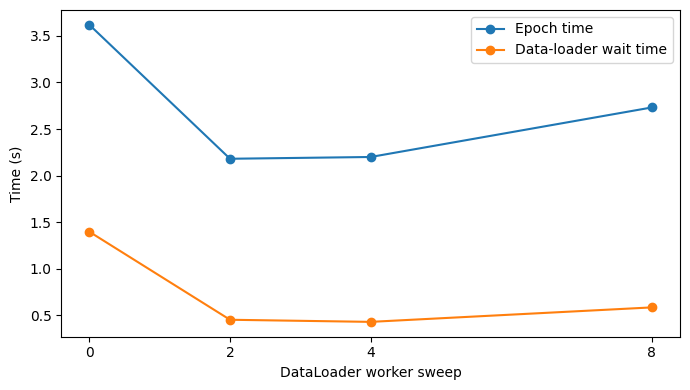

In [28]:
if FULL_SCALE:
    import pandas as pd
    import matplotlib.pyplot as plt

    worker_table = pd.DataFrame([
        {
            "num_workers": nw,
            "Data-loader wait time (s)": load_times[nw],
            "Epoch time (s)": epoch_times[nw],
        }
        for nw in (0, 2, 4, 8)
    ])

    display(worker_table.round(4))

    best_worker = min(epoch_times,key=epoch_times.get)
    print("Fastest for num_workers:", best_worker)

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        worker_table["num_workers"],
        worker_table["Epoch time (s)"],
        marker="o",
        label="Epoch time",
    )
    ax.plot(
        worker_table["num_workers"],
        worker_table["Data-loader wait time (s)"],
        marker="o",
        label="Data-loader wait time",
    )

    ax.set_xticks([0, 2, 4, 8])
    ax.set_xlabel("DataLoader worker sweep")
    ax.set_ylabel("Time (s)")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [29]:
def transfer_step(model, batch, optimizer, device, non_blocking):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    device_batch = { name: tensor.to(device, non_blocking=non_blocking) for name, tensor in batch.items()}

    outputs = model(**device_batch)
    outputs.loss.backward()
    optimizer.step()

    return outputs.loss.item()


if FULL_SCALE:
    pin_results = []

    for pin_memory, non_blocking in [(False, False), (True, True), (True, False), (False, True)]:
        torch.manual_seed(SEED)

        model = build_model(build_tiny_config()).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

        loader = DataLoader(
            IMDBDataset(train_rows, tokenizer, max_len=64),
            batch_size=16,
            shuffle=True,
            collate_fn=collate_fn,
            num_workers=best_worker,
            pin_memory=pin_memory,
            generator=torch.Generator().manual_seed(SEED),
        )

        # warm up executions
        warmup = collate_fn([{"input_ids": tokenize_function(row["text"], tokenizer, 64),"label": row["label"],}for row in train_rows[:16]])

        if pin_memory:
            warmup_batch = {name: tensor.pin_memory() for name, tensor in warmup.items()}

        for _ in range(3):
            transfer_step(model, warmup, optimizer, DEVICE, non_blocking)

        torch.cuda.synchronize(DEVICE)
        start = time.perf_counter()

        iterator = iter(loader)
        first_batch_pinned = None

        for step in range(len(loader)):
            batch = next(iterator)

            if step == 0:
                first_batch_pinned = all(tensor.is_pinned() for tensor in batch.values())

            transfer_step(model, batch, optimizer, DEVICE, non_blocking)

        torch.cuda.synchronize(DEVICE)
        elapsed = time.perf_counter() - start

        pin_results.append({
            "num_workers": best_worker,
            "pin_memory": pin_memory,
            "non_blocking": non_blocking,
            "CPU batch pinned": first_batch_pinned,
            "Epoch time (s)": elapsed,
        })

        del iterator, loader, model, optimizer, warmup, batch

    pin_table = pd.DataFrame(pin_results)
    display(pin_table)

,num_workers,pin_memory,non_blocking,CPU batch pinned,Epoch time (s)
0,2,False,False,False,1.443891
1,2,True,True,True,1.392230
2,2,True,False,True,1.401509
3,2,False,True,False,1.407986


In [30]:
def profiled_step(model, batch, optimizer, device):
    """Run one training step with the forward, backward, and optimizer regions
    each wrapped in torch.profiler.record_function("forward" / "backward" /
    "optimizer"). Return the loss as a Python float."""
    model.train()
    optimizer.zero_grad(set_to_none=True)

    with torch.profiler.record_function("host_to_device"):
        device_batch = {name: tensor.to(device, non_blocking=True) for name, tensor in batch.items()}

    with torch.profiler.record_function("forward"):
        outputs = model(**device_batch)
        loss = outputs.loss

    with torch.profiler.record_function("backward"):
        loss.backward()

    with torch.profiler.record_function("optimizer"):
        optimizer.step()

    return loss.item()

if FULL_SCALE:
    from torch.profiler import profile, ProfilerActivity, record_function

    os.makedirs("traces", exist_ok=True)

    model = build_model(build_tiny_config()).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

    for pin in (False, True):
        loader = DataLoader(
            IMDBDataset(train_rows, tokenizer, max_len=64),
            batch_size=16,
            num_workers=2,
            pin_memory=pin,
            collate_fn=collate_fn,
        )
        batches = iter(loader)

        # warm up thrice
        for _ in range(3):
            profiled_step(model, next(batches), opt, DEVICE)

        torch.cuda.synchronize(DEVICE)

        with profile(
            activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
            record_shapes=True,
        ) as p:
            for _ in range(3):
                with record_function("data_loading"):
                    batch = next(batches)

                profiled_step(model, batch, opt, DEVICE)

        path = f"traces/c3_pin_{pin}.json"
        p.export_chrome_trace(path)
        print("Saved:", path)

        del batches, loader

    del model, opt

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Saved: traces/c3_pin_False.json
Saved: traces/c3_pin_True.json


_Your C3 write-up: the num_workers plot and the best setting; the pin_memory + non_blocking overlap finding._

Best setting: num_workers=2 or 4 (both perform similarly)
It gave the shortest epoch. Background batch preparation reduced DataLoader waiting. num_workers=4 only gives little benefit and num_workers=8 increased both waiting and epoch time. I saw a PyTorch warning that eight workers exceeds the suggested maximum of four.

Some runs favor num_workers=4 while this run shows num_workers=2, so I do not see reproducible best setting.

---

At num_workers=2, I compared pin_memory + non_blocking settings:

{pin_memory + non_blocking}={True, True} reduces epoch time by about ~7% compared to baseline {pin_memory + non_blocking}={False, False}. The fastest setting was {pin_memory + non_blocking}={True, False}. 

FYI: I do not observe a consistent ranking across multiple runs. Only the batch checks ensure that pinning worked.

---

Following C4 profiling setup, I added additional short trace to see the copy overlap with GPU. Both traces have non_blocking=True, only pin_memory is changed {True or False}. 

In both traces, copies and compute kernels use CUDA stream 7. I do not see overlap in their recorded time intervals. So we conclude pin_memory with non_blocking transfers does not produce significant copy/compute overlap in this run.
The ~7% improvement cannot be attributed to copy/compute overlap. Also a single run
is unable to establish a consistent speedup.

pin_memory: True

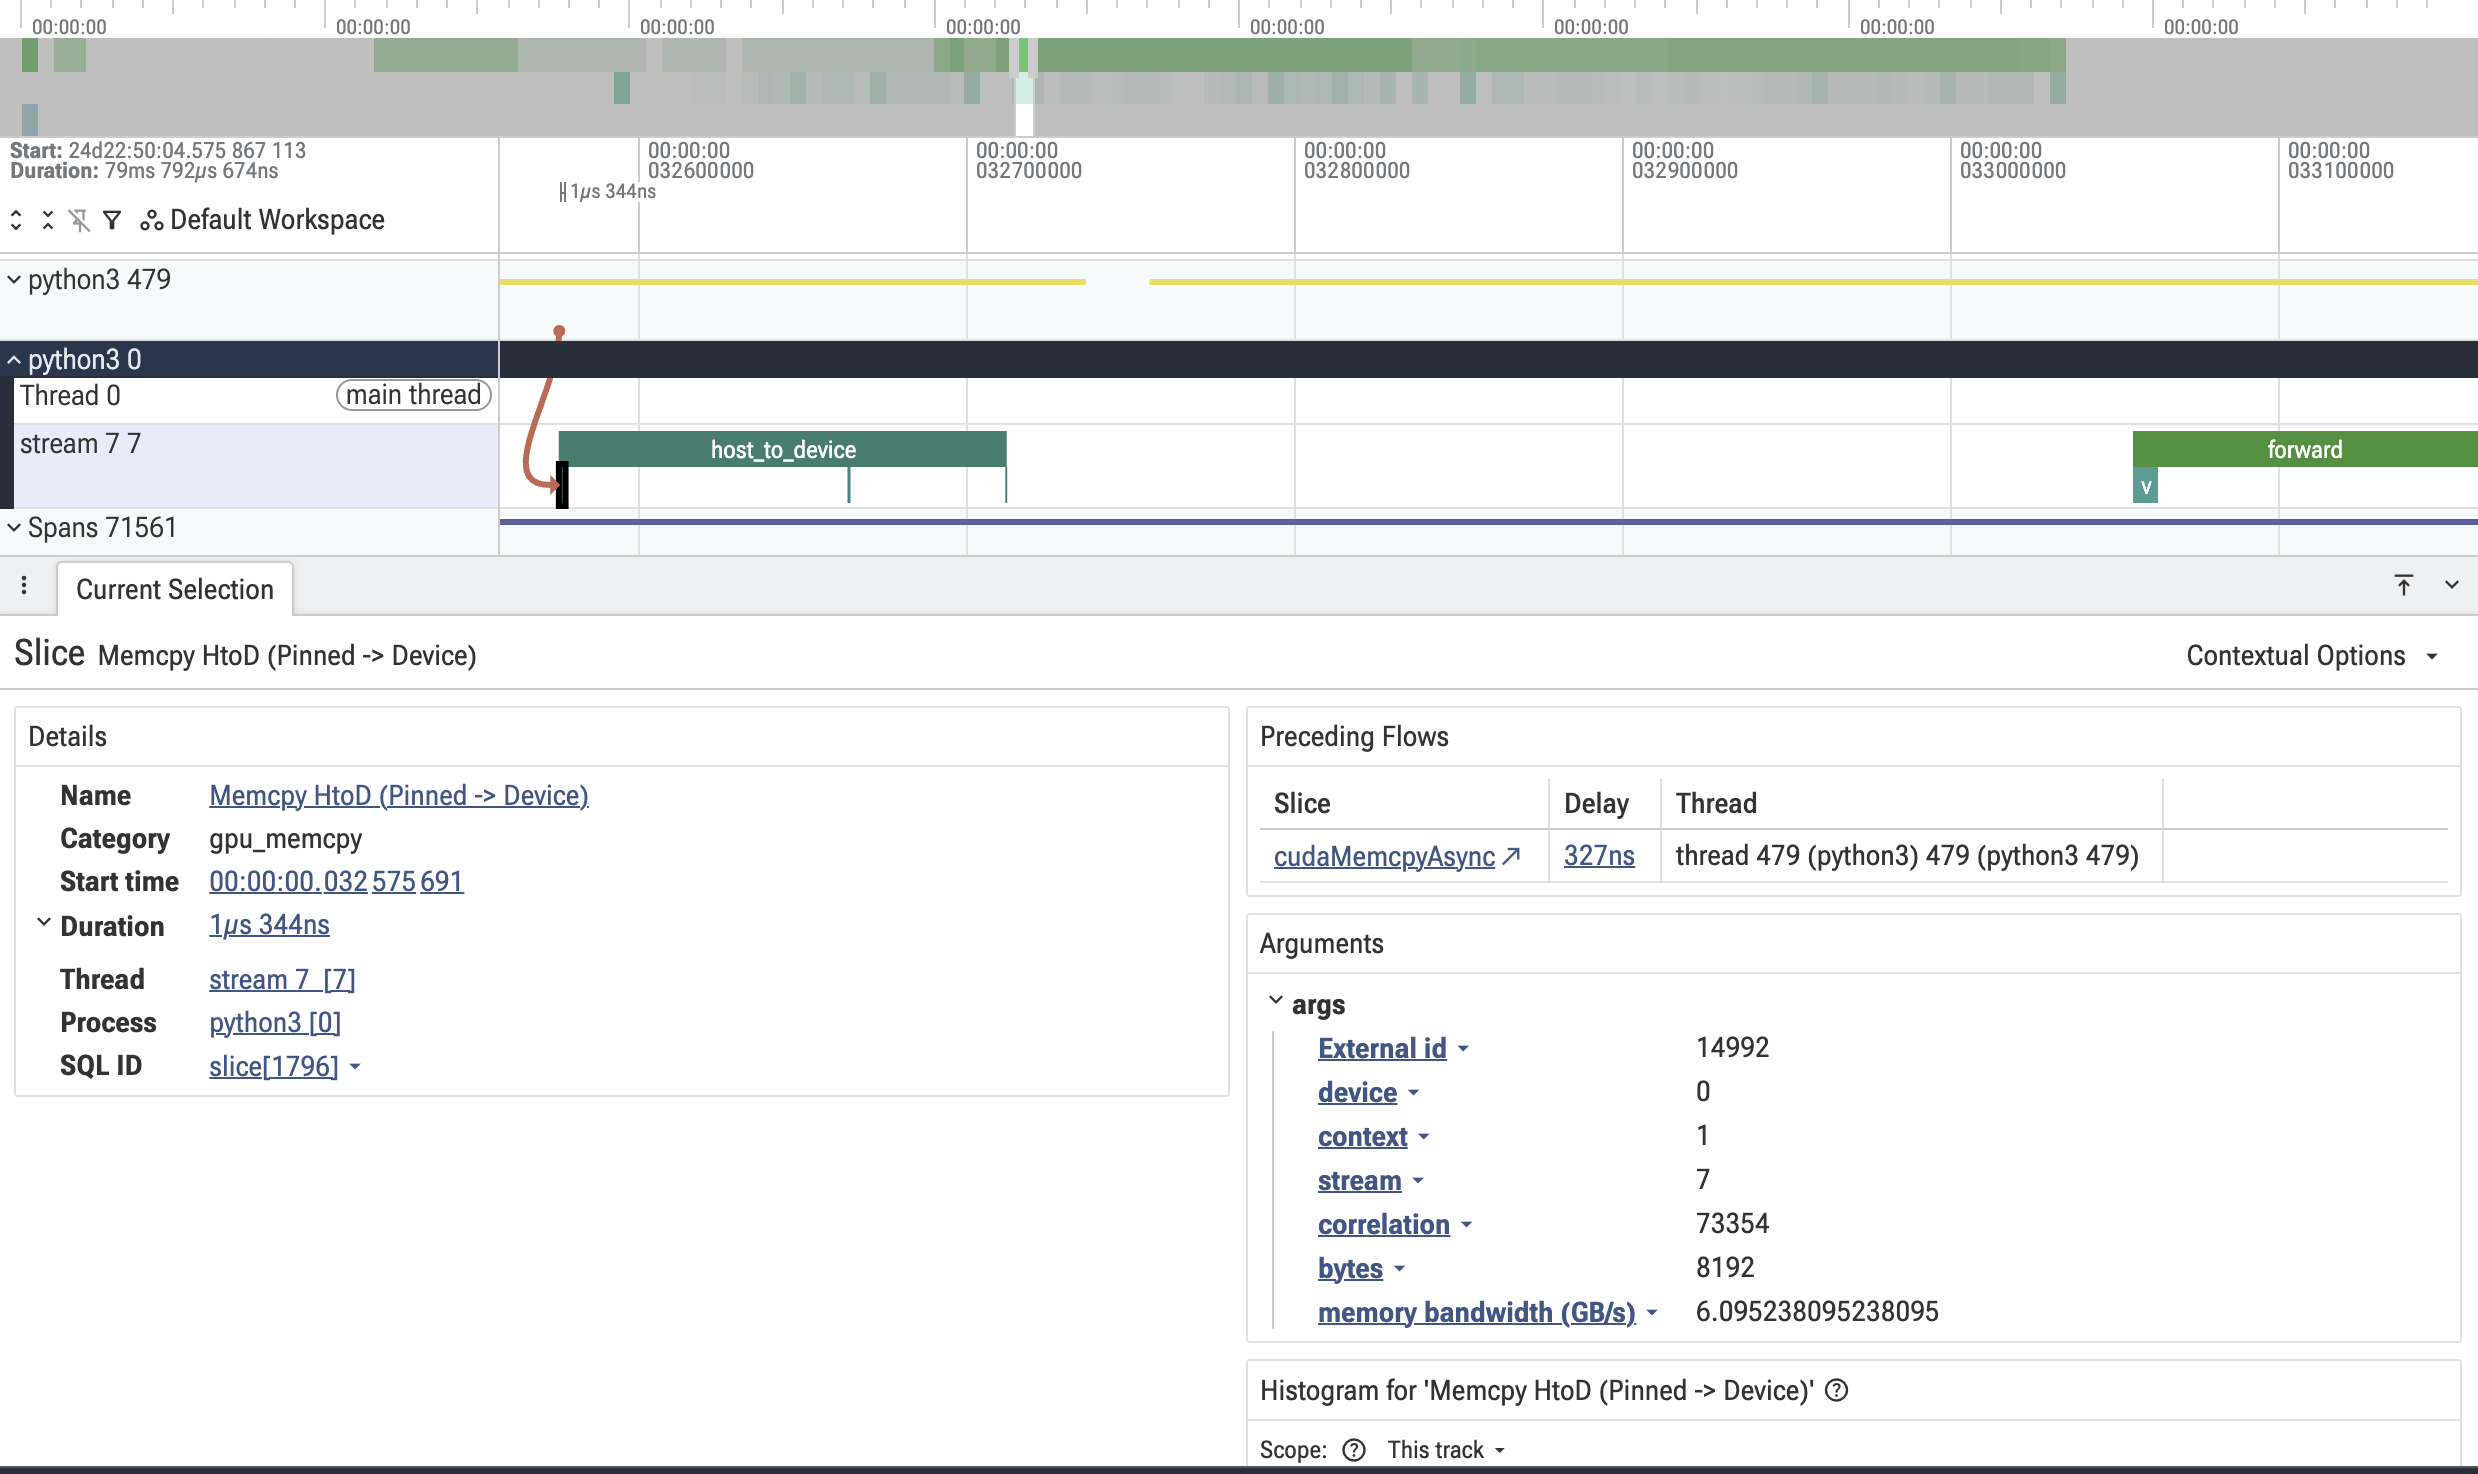


pin_memory: False

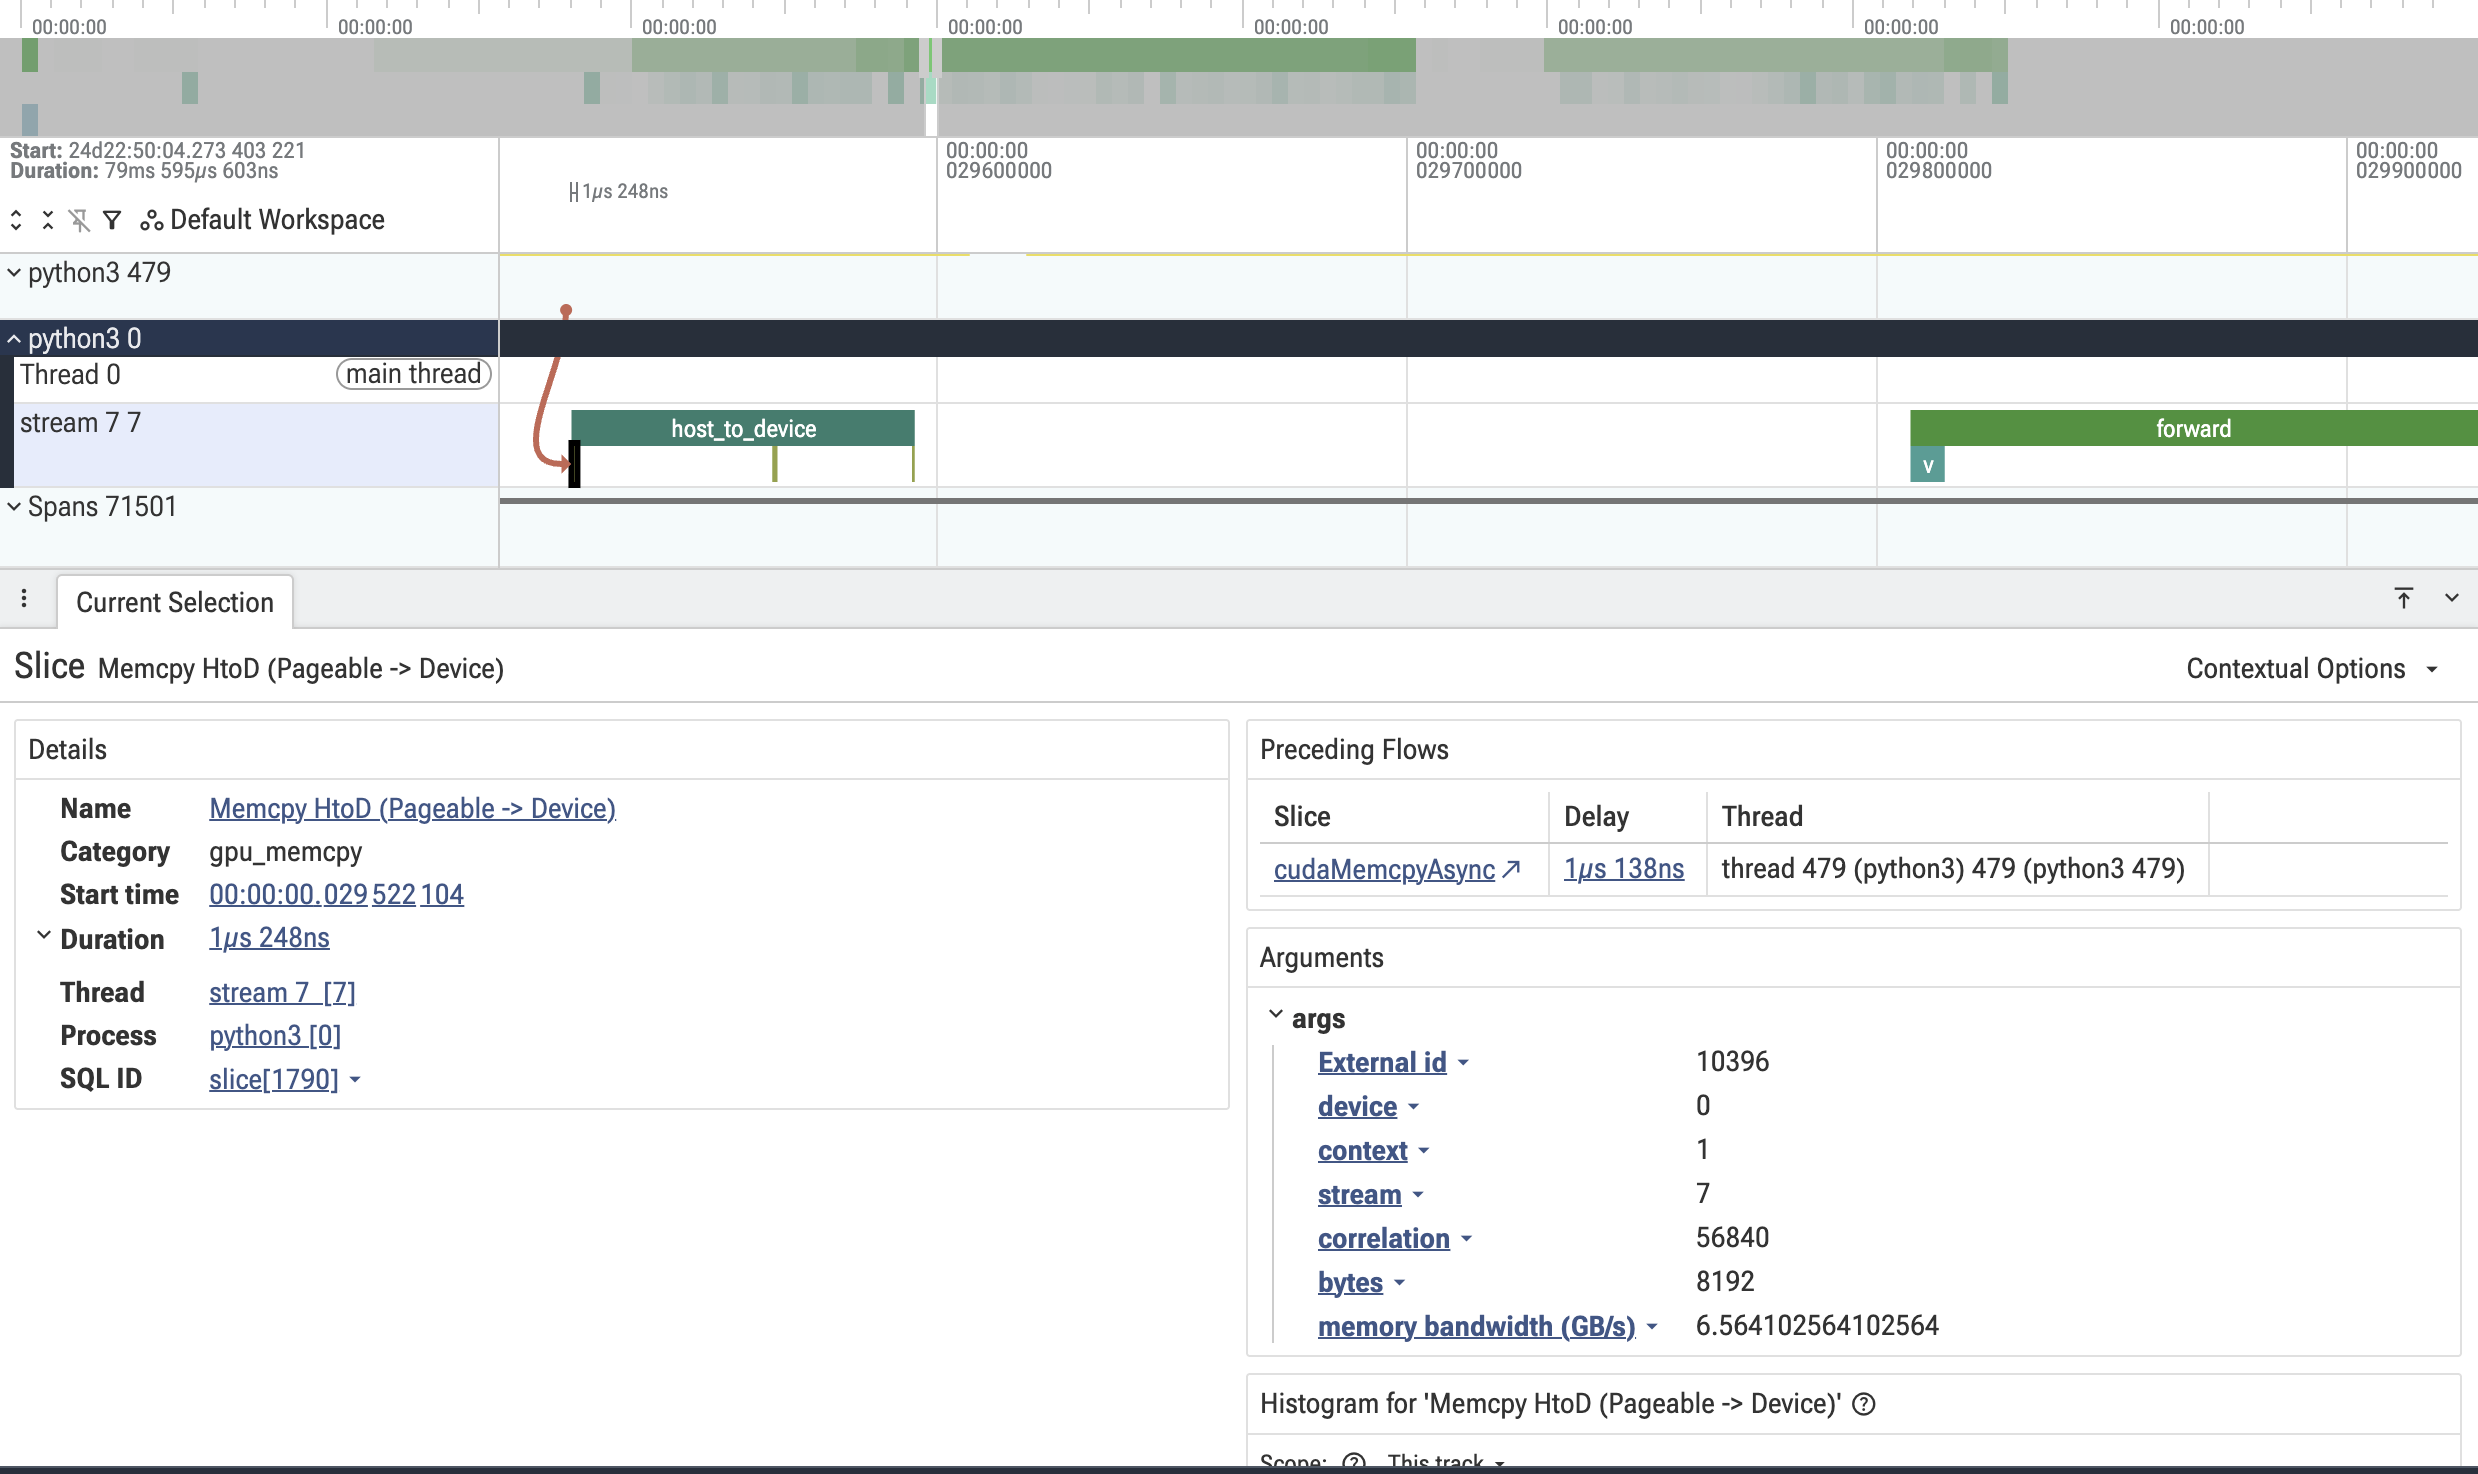

## C4 (15 pts): Profiler-based bottleneck diagnosis

Implement `make_profiler_schedule()` (a correct wait/warmup/active schedule) and
`profiled_step(...)` (forward/backward/optimizer wrapped in `record_function`).
Then classify the step as launch-bound, GPU-compute-bound, or input-bound, with a
batch-scaling test plus two trace features.

**Your turn.** Return a `torch.profiler.schedule` with a real wait, warmup, and active phase so you profile steady-state steps, not the warm-up.

In [31]:
def make_profiler_schedule(wait=1, warmup=1, active=3, repeat=1):
    """Return a torch.profiler.schedule(...) with a nonzero wait, warmup, and
    active phase, so the profiler records steady-state steps."""
    return torch.profiler.schedule(wait=wait, warmup=warmup, active=active, repeat=repeat)

In [32]:
grader.check("q_profiler_schedule")

q_profiler_schedule results: All test cases passed!

**Your turn.** Wrap the forward, backward, and optimizer regions of a training step in `torch.profiler.record_function` labels named `forward`, `backward`, and `optimizer`, and return the loss as a float.

In [33]:
def profiled_step(model, batch, optimizer, device):
    """Run one training step with the forward, backward, and optimizer regions
    each wrapped in torch.profiler.record_function("forward" / "backward" /
    "optimizer"). Return the loss as a Python float."""
    model.train()
    optimizer.zero_grad(set_to_none=True)

    # Nonblocking = Ture as per C3.
    with torch.profiler.record_function("host_to_device"):
        device_batch = {name: tensor.to(device, non_blocking=True) for name, tensor in batch.items()}

    with torch.profiler.record_function("forward"):
        outputs = model(**device_batch)
        loss = outputs.loss

    with torch.profiler.record_function("backward"):
        loss.backward()

    with torch.profiler.record_function("optimizer"):
        optimizer.step()

    return loss.item()

In [34]:
grader.check("q_record_function")

q_record_function results: All test cases passed!

In [35]:
from torch.profiler import profile, ProfilerActivity
import os

def batch_scaling_test(sizes=(8, 16, 32, 64)):
    """Time one training step at each batch size (after a short warm-up) on the
    tiny model, and return a dict mapping batch size to per-step seconds. Flat
    times as the batch grows point to a launch-bound step."""
    # BEGIN SOLUTION
    out = {}
    model = build_model(build_tiny_config()).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    pool = (tiny_rows * 4)
    for bs in sizes:
        batch = collate_fn([{"input_ids": tokenize_function(r["text"], tokenizer, 64), "label": r["label"]} for r in pool[:bs]])
        for _ in range(2):
            time_training_step(model, batch, opt, DEVICE)
        out[bs] = time_training_step(model, batch, opt, DEVICE)["total"]
    return out
    # END SOLUTION

activities = [ProfilerActivity.CPU] + ([ProfilerActivity.CUDA] if FULL_SCALE else [])
_m = build_model(build_tiny_config()).to(DEVICE)
_o = torch.optim.AdamW(_m.parameters(), lr=1e-3)
print("schedule actions:", [str(make_profiler_schedule()(i)).split(".")[-1] for i in range(6)])
os.makedirs("traces", exist_ok=True)
with profile(activities=activities, record_shapes=True) as prof:
    for _ in range(3):
        profiled_step(_m, _demo_batch, _o, DEVICE)
prof.export_chrome_trace("traces/hw2_c4_trace.json")
print("per-step total vs batch size:", {k: round(v, 5) for k, v in batch_scaling_test().items()})
print("wrote traces/hw2_c4_trace.json")
print(prof.key_averages().table(row_limit=100))

schedule actions: ['NONE', 'WARMUP', 'RECORD', 'RECORD', 'RECORD_AND_SAVE', 'NONE']
per-step total vs batch size: {8: 0.00759, 16: 0.00784, 32: 0.00774, 64: 0.00854}
wrote traces/hw2_c4_trace.json
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                    Optimizer.zero_grad#AdamW.zero_grad         0.38%     208.413us         0.38%     208.413us      69.471us       0.000us         0.00%       0.000us       0.000us             3  
          

In [36]:
for event in prof.key_averages():
    if (
        event.key in ("host_to_device", "forward", "backward", "optimizer")
        and event.cpu_time_total > 0
    ):
        print(
            f"{event.key}: "
            f"{event.cpu_time_total / 1000:.3f} ms total, "
            f"{event.cpu_time_total / event.count / 1000:.3f} ms per call"
        )

host_to_device: 2.846 ms total, 0.949 ms per call
forward: 13.228 ms total, 4.409 ms per call
backward: 17.907 ms total, 5.969 ms per call
optimizer: 6.913 ms total, 2.304 ms per call


_Your C4 write-up: the regime classification (launch-bound / compute-bound / input-bound), the batch-scaling evidence, two trace features, and the one change you would make first._


I would classify this tiny-model workload as launch-bound, along with some CPU overhead. The batch-size experiment supports this:

| Batch size | Per-step time (ms) |
|---|---:|
| 8 | 7.59 |
| 16 | 7.84 |
| 32 | 7.74 |
| 64 | 8.54 |

As batch size increased from 8 to 64, step time increased by ~13% only. We can say that fixed overhead is significant for tiny model.

---

The profiler recorded the following CPU region durations:

```
host_to_device: 2.846 ms total, 0.949 ms per call
forward: 13.228 ms total, 4.409 ms per call
backward: 17.907 ms total, 5.969 ms per call
optimizer: 6.913 ms total, 2.304 ms per call
```

Backward was the longest, followed by forward. These are only CPU-side durations for each phase and not measuring continuous GPU computation. As stated previously, batch was prepared beforehand so data-loader waiting isn't included. Only transfer is measured in host_to_device.

Profiling evidence to support the launch-bound claim.
- I see 572 cudaLaunchKernel calls across 3 steps, and it takes ~5 ms of CPU time. 
- Many GPU kernels were short like 3–5 microseconds average.
So we say that this workload launches many small operations rather than few long kernels.

CPU (around 55 ms) and GPU (around 6.4 ms) execution time may have overlapped.

My first change would be to test torch.compile so as to combine operations and reduce the number of cudaLaunchKernel calls + its CPU overhead. Comparing warmed-up step time v/s eager-execution would help.

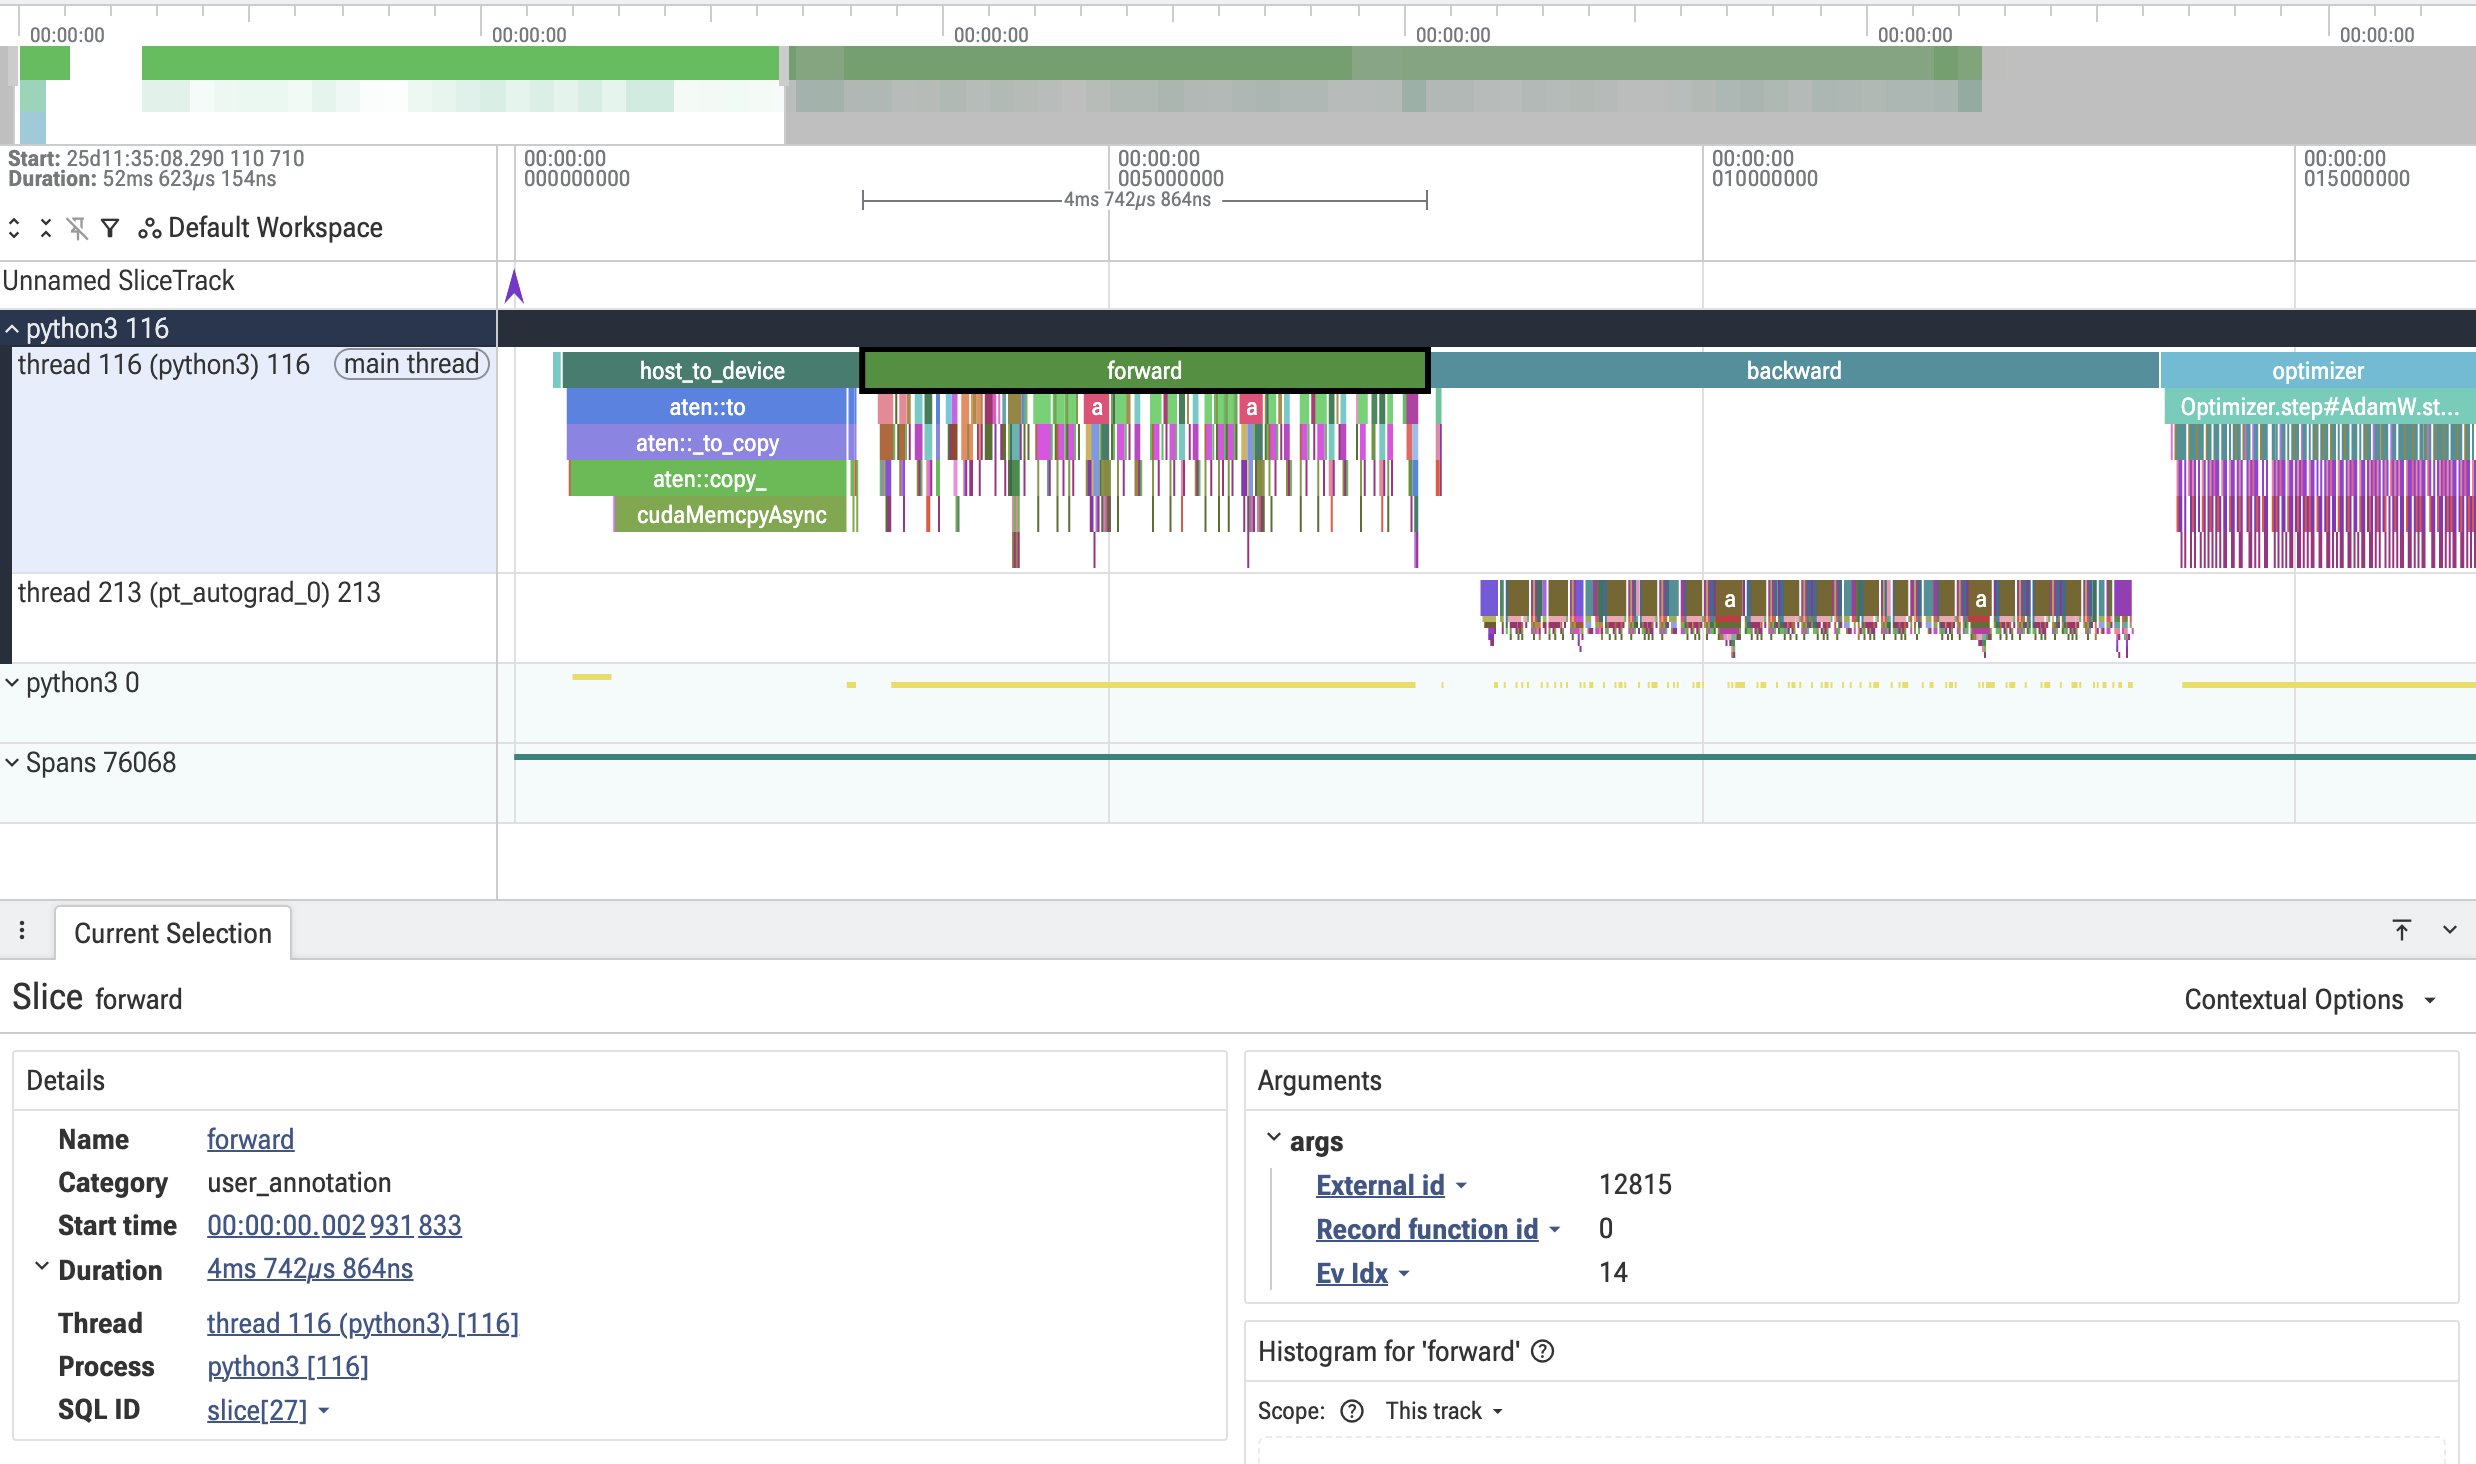

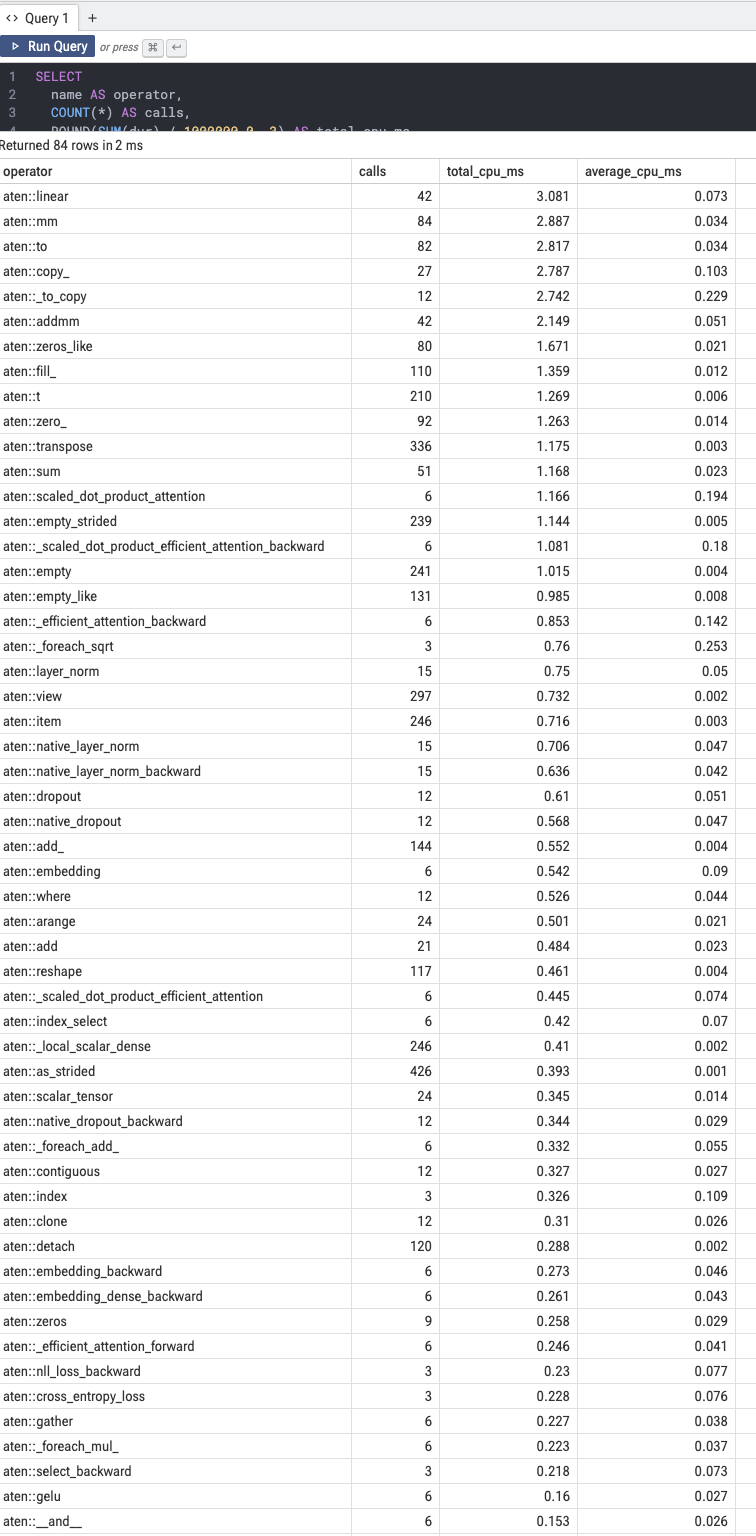

## C5 (10 pts): Graph breaks

Report `gb_before` and `gb_after`: the graph-break count of a function with a
data-dependent branch, and of a branchless rewrite that removes the break. On
your GPU run, also apply this to the model and show the break in a trace.

**Your turn.** Set `gb_before` to the graph-break count of a function with a data-dependent Python branch, and `gb_after` to the count after a branchless rewrite (use `torch._dynamo.explain`).

In [37]:
import torch._dynamo as dynamo

def fn_with_break(x):
    if x.sum() > 0:
        return x * 2
    else:
        return x - 2

def fn_fixed(x):
    return torch.where(x.sum() > 0, x * 2, x - 2)

_x = torch.randn(16)
dynamo.reset()
gb_before = dynamo.explain(fn_with_break)(_x).graph_break_count
dynamo.reset()
gb_after = dynamo.explain(fn_fixed)(_x).graph_break_count
print(f"graph breaks: before={gb_before} after={gb_after}")

graph breaks: before=1 after=0


In [38]:
grader.check("q_graph_break_counts")

q_graph_break_counts results: All test cases passed!

In [39]:
if FULL_SCALE:
    model = build_model(build_tiny_config()).to(DEVICE)

    batch = {name: tensor.to(DEVICE) for name, tensor in _demo_batch.items() }

    explanation = dynamo.explain(model)(**batch)

    print("Model graph count:", explanation.graph_count)
    print("Model graph breaks:", explanation.graph_break_count)

    for reason in explanation.break_reasons:
        print(reason)

    del model, batch

Model graph count: 1
Model graph breaks: 0


In [40]:
if FULL_SCALE:
    from torch.profiler import profile, ProfilerActivity, record_function

    os.makedirs("traces", exist_ok=True)
    x = torch.ones(16, device=DEVICE)

    for name, fn in (
        ("before", fn_with_break),
        ("after", fn_fixed),
    ):
        compiled_fn = torch.compile(fn)

        for _ in range(3):
            result = compiled_fn(x)

        torch.cuda.synchronize(DEVICE)

        with profile(
            activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
            record_shapes=True,
        ) as p:
            for _ in range(3):
                with record_function(name):
                    result = compiled_fn(x)

            torch.cuda.synchronize(DEVICE)

        path = f"traces/c5_{name}.json"
        p.export_chrome_trace(path)
        print("Saved:", path)

Saved: traces/c5_before.json
Saved: traces/c5_after.json


_Your C5 write-up: the graph-break causes, the fix you made, and the before/after in a trace._

The graph-break count drops from 1 to 0. The original function had if-condition on x (making it data-dependent), so Python must read the tensor condition to decide what to return causing a graph break. We replace that branch with `torch.where(x.sum() > 0, x * 2, x - 2)` so that selection happens within the torch operation.

Additionally, the tiny_model forward pass showed 1 graph and 0 graph-breaks.

---

Before: Two compiled graphs (aten::is_nonzero and scalar extraction) and graph break visible between them to resolve the data-dependent Python condition.

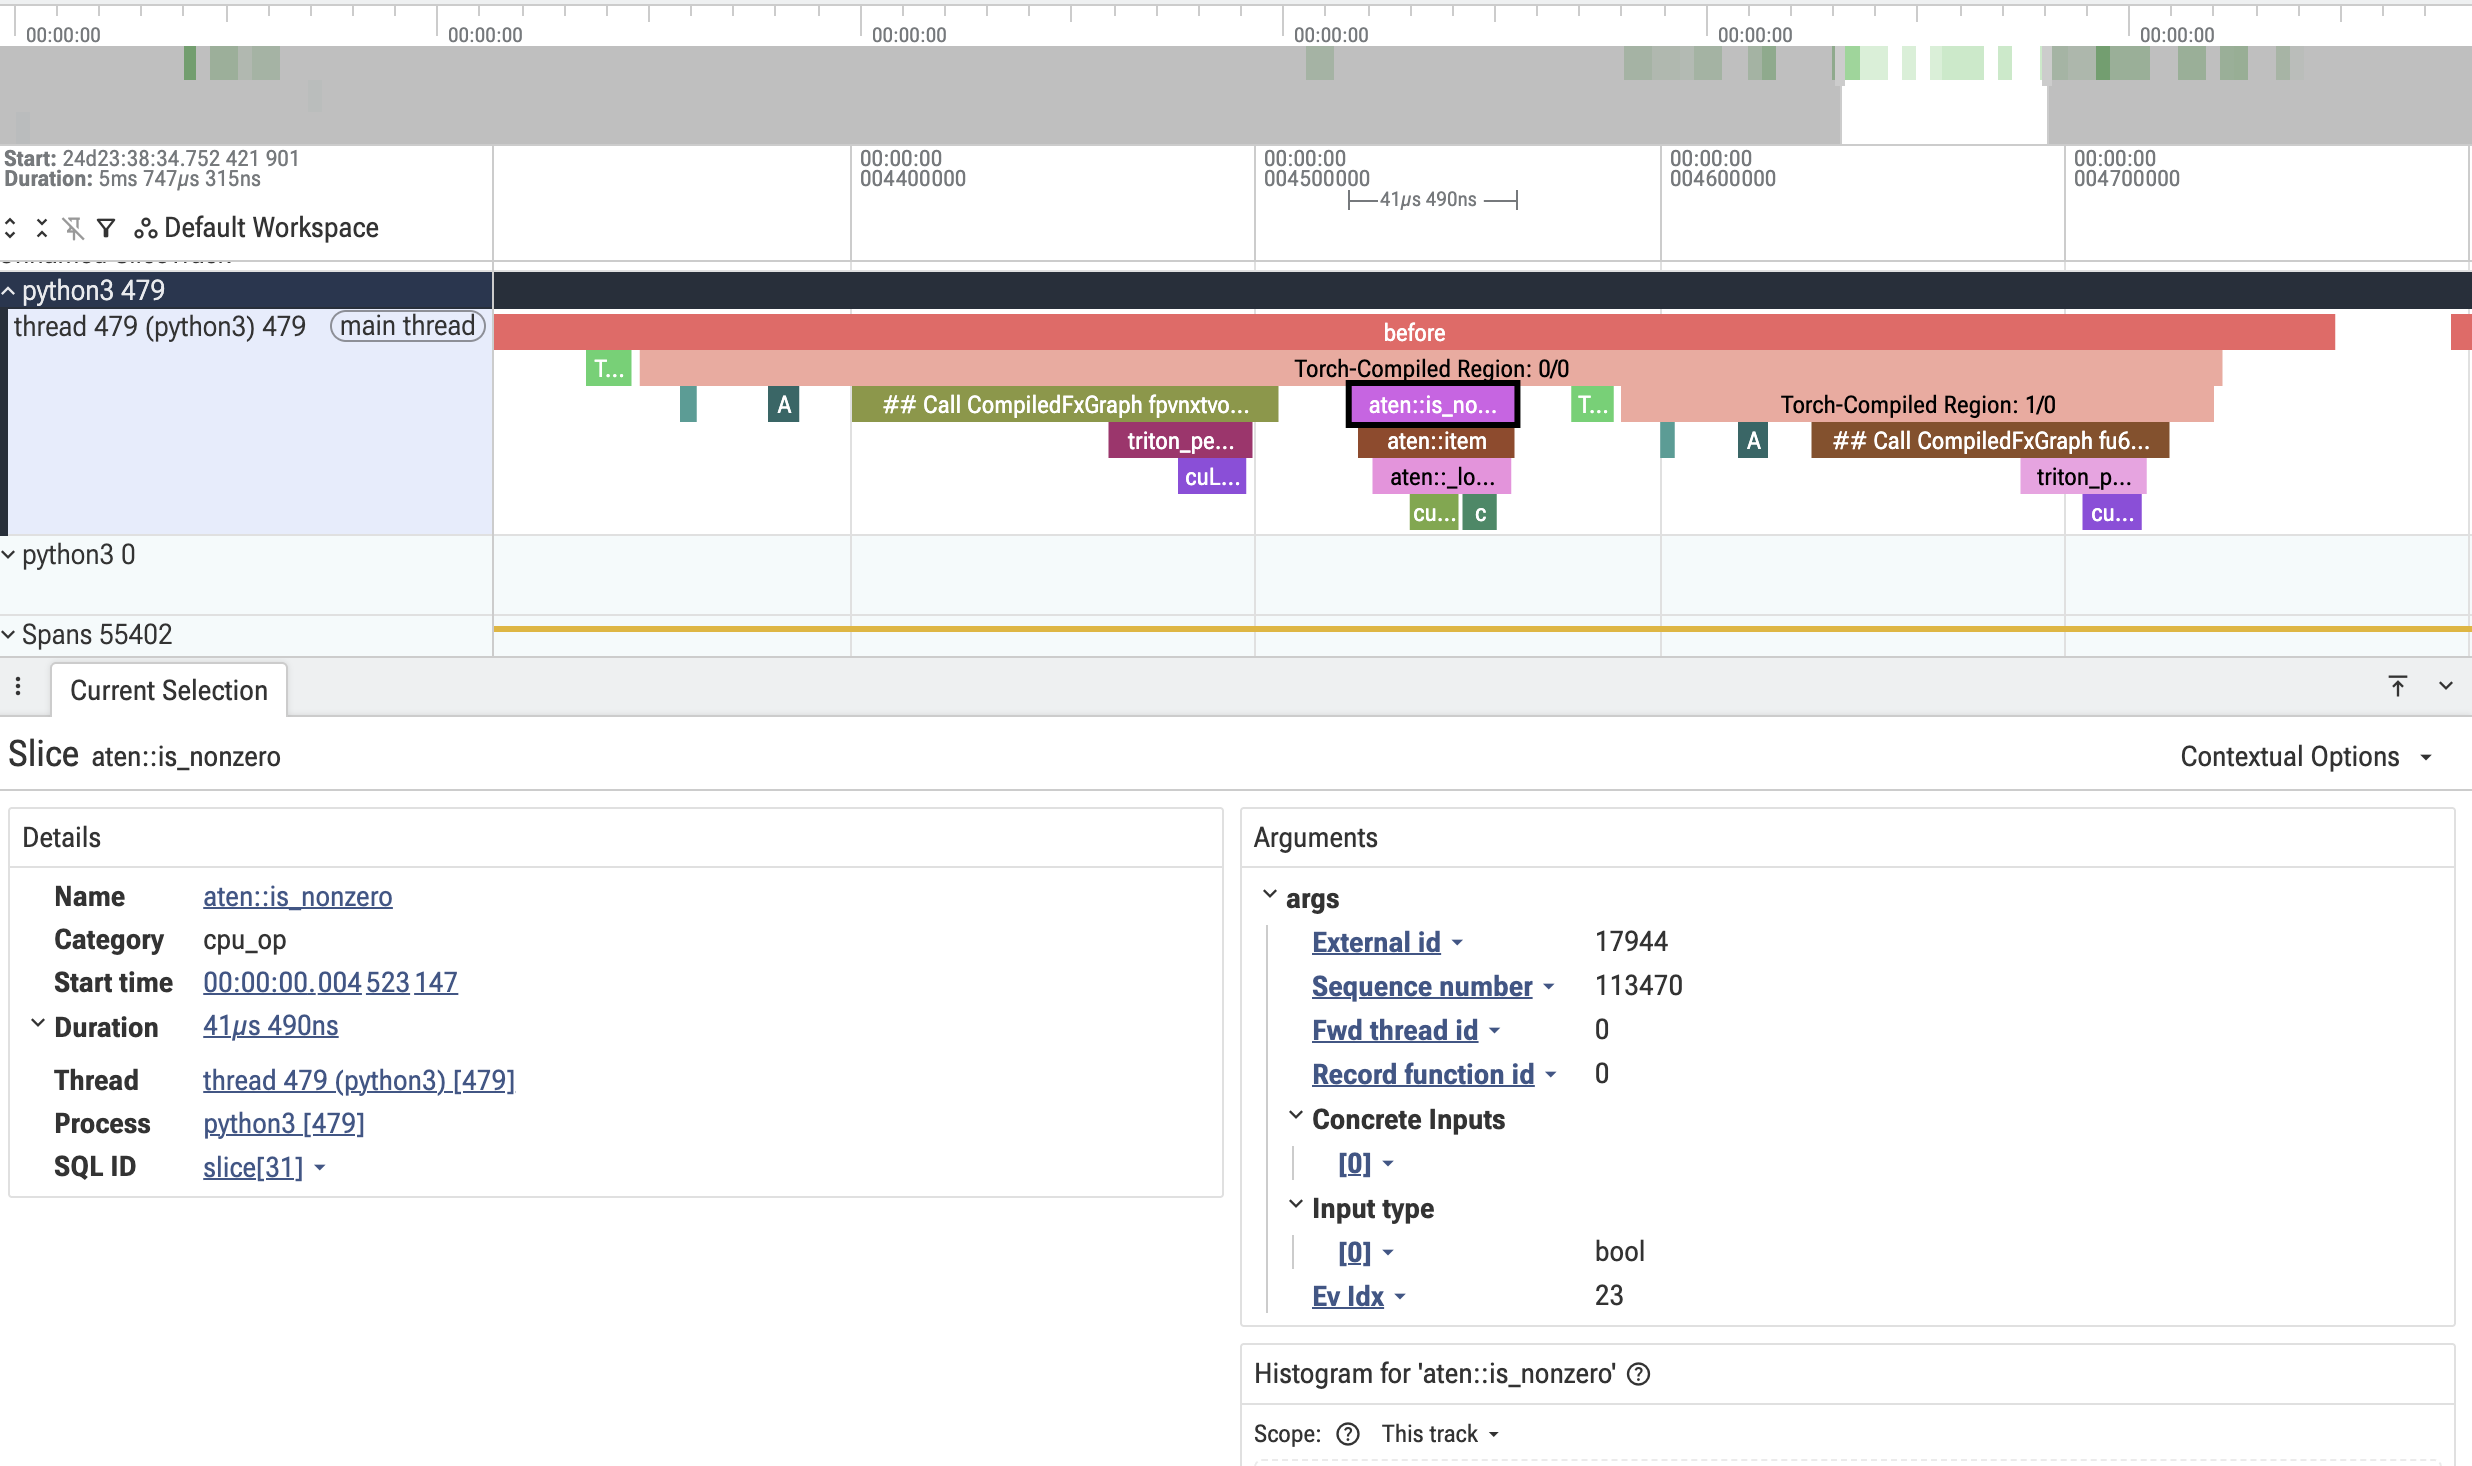

After: Only single compiled graph, so no breaks

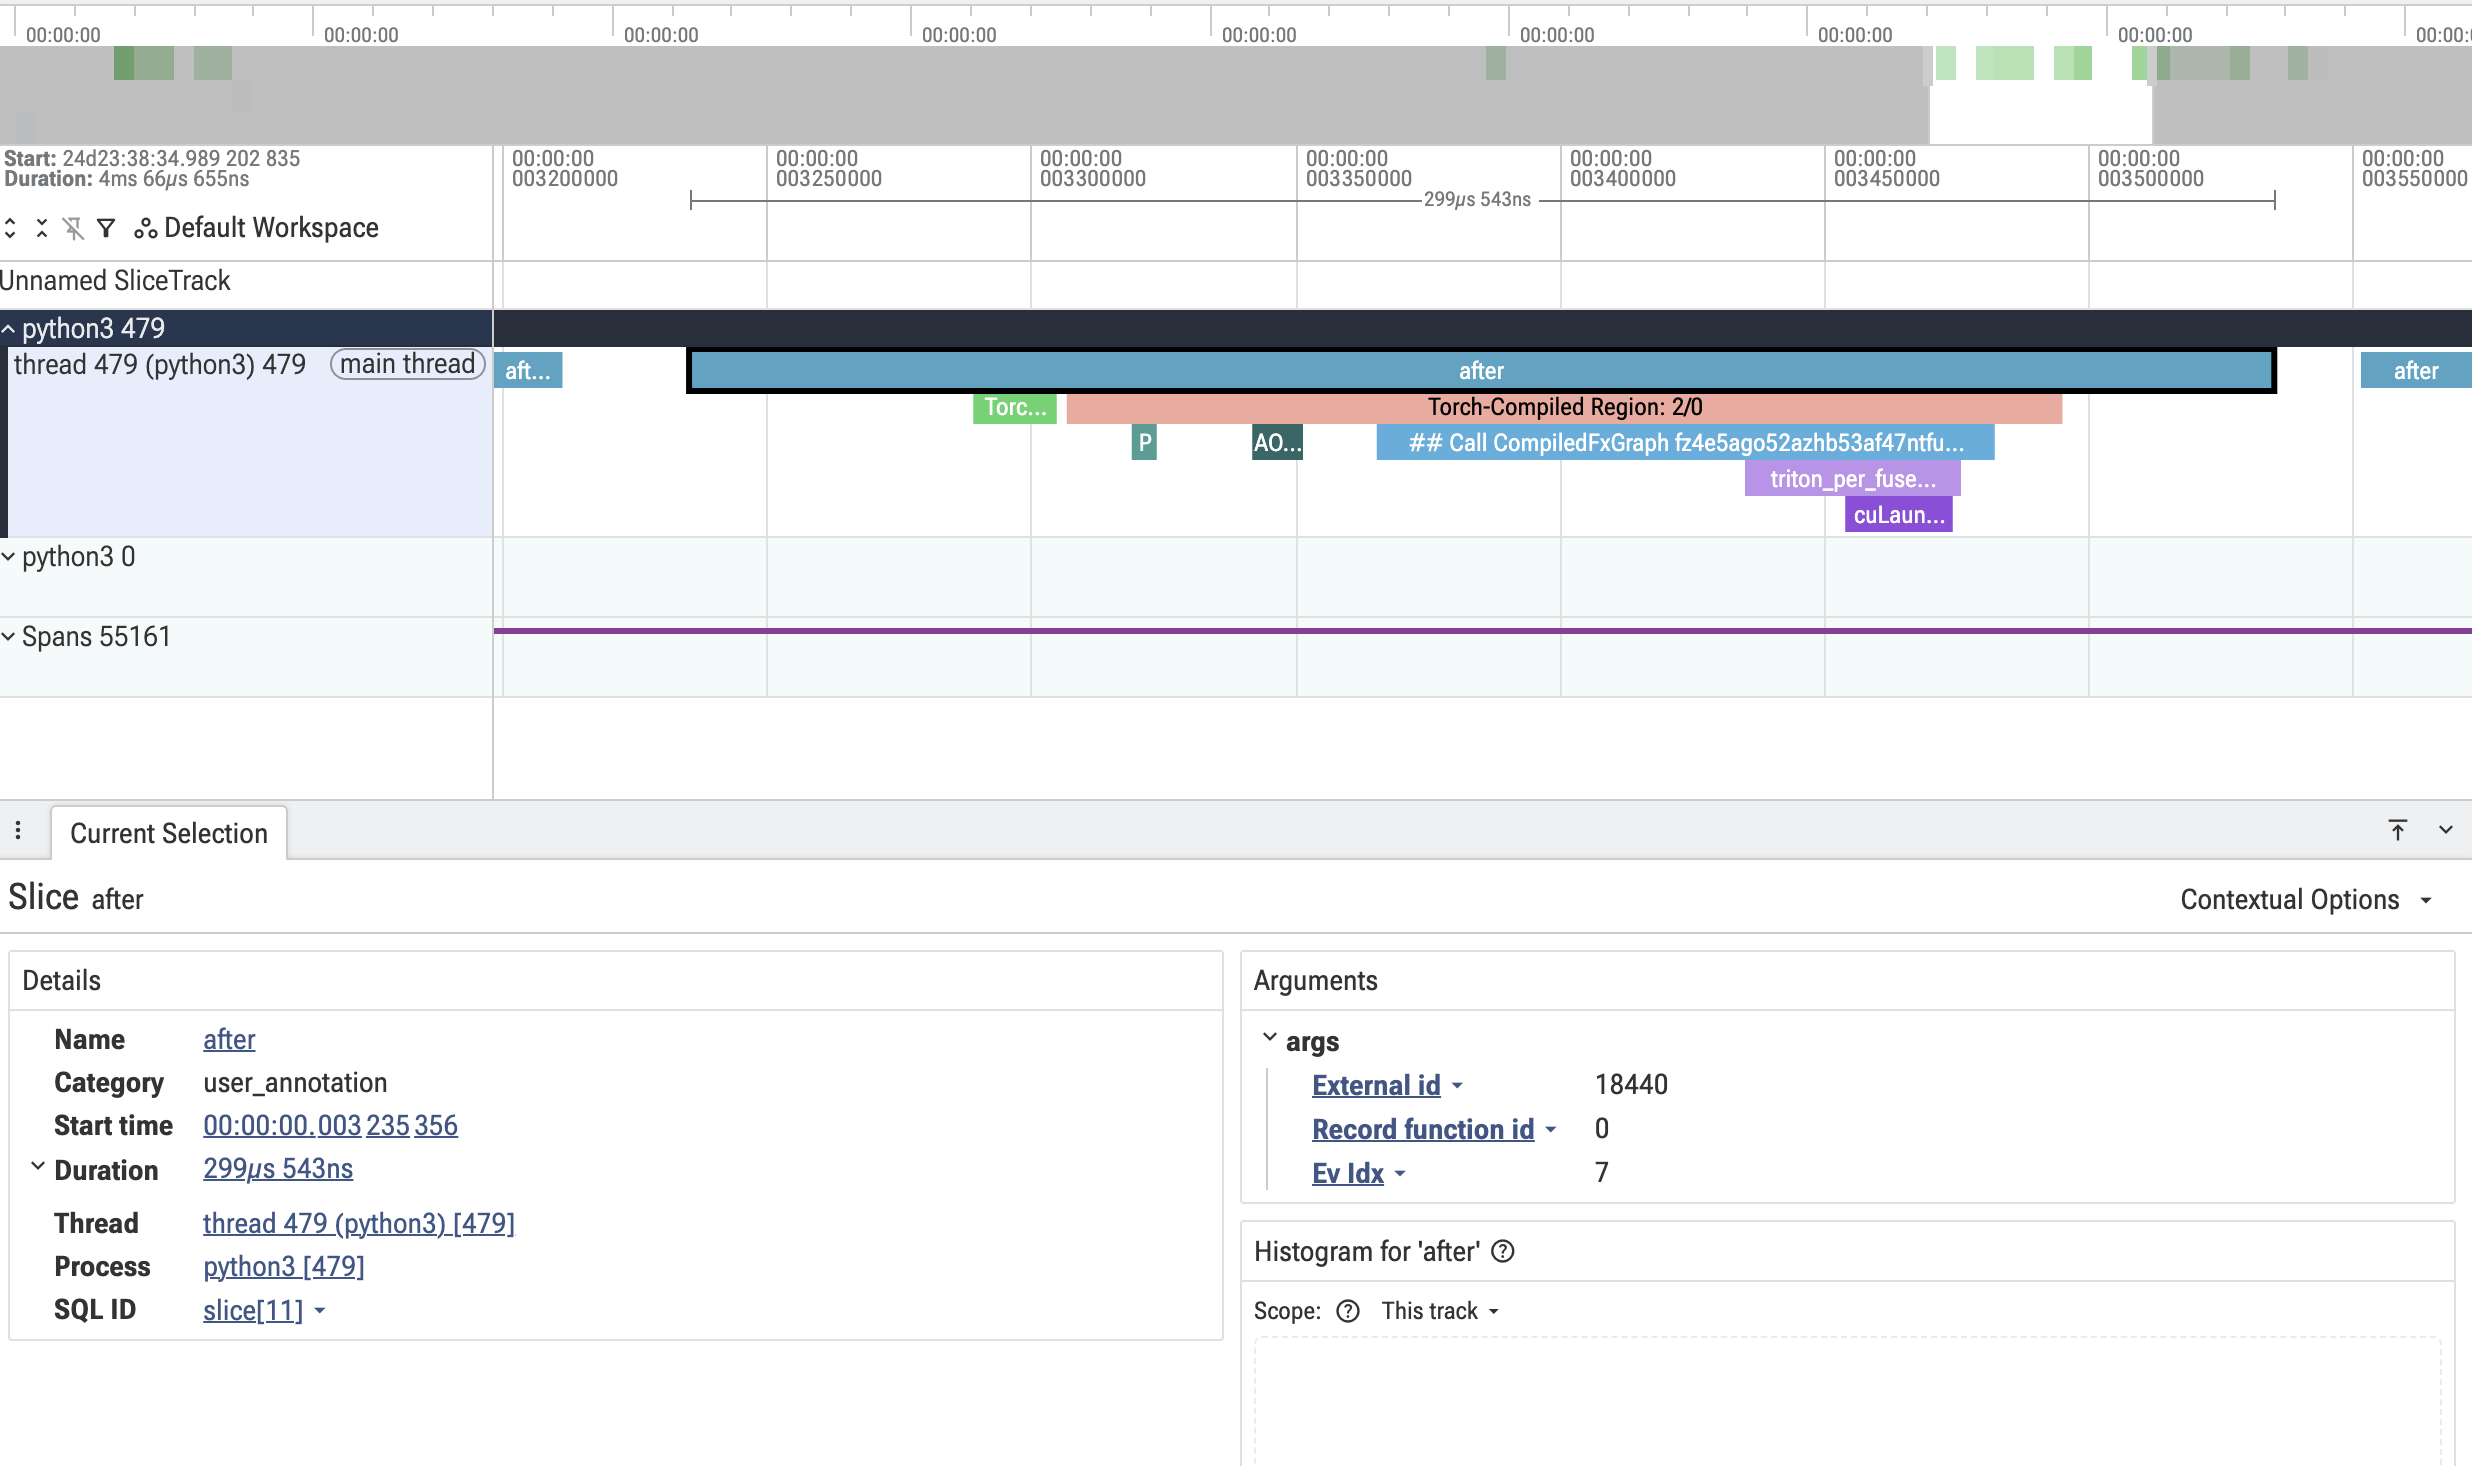

## C6 (12 pts): torch.compile performance and break-even

Eager vs compiled step time, the one-time compile cost, the break-even step
count, and one non-default mode.

In [41]:
def avg_step_time(step_model, batch, opt, device, iters=10):
    """Return the average seconds per training step over `iters` steps, after a
    short warm-up, with the GPU synchronized around the timed region."""
    # BEGIN SOLUTION
    for _ in range(3):
        train_one_step(step_model, batch, opt, device)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(iters):
        train_one_step(step_model, batch, opt, device)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t) / iters
    # END SOLUTION

# if FULL_SCALE:
#     base = build_model(build_tiny_config()).to(DEVICE)
#     opt = torch.optim.AdamW(base.parameters(), lr=1e-3)
#     eager = avg_step_time(base, _demo_batch, opt, DEVICE)
#     compiled = torch.compile(base)
#     t0 = time.perf_counter()
#     train_one_step(compiled, _demo_batch, opt, DEVICE)
#     torch.cuda.synchronize()
#     compile_cost = time.perf_counter() - t0
#     comp = avg_step_time(compiled, _demo_batch, opt, DEVICE)
#     breakeven = compile_cost / max(eager - comp, 1e-9)
#     print(f"[GPU] eager={eager*1e3:.2f}ms compiled={comp*1e3:.2f}ms "
#           f"compile_cost={compile_cost:.2f}s break-even={breakeven:.0f} steps")
# else:
#     print("[CPU] C6 compile timing runs on your GPU box. "
#           "break-even = compile_cost / (eager_step - compiled_step).")

if FULL_SCALE:
    results = []
    for mode in ("eager", "default", "reduce-overhead"):
        torch.manual_seed(SEED)
        model = build_model(build_tiny_config()).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
        # 3 warm up eager executions
        for _ in range(3):
            train_one_step(model, _demo_batch, opt, DEVICE)
        if mode == "eager":
            eager = avg_step_time(model, _demo_batch, opt, DEVICE)
            results.append({
                "Mode": mode,
                "Step time (ms)": eager * 1000,
                "First compile step (s)": None,
                "Startup overhead (s)": None,
                "Speedup": 1.0,
                "Break-even steps": None,
            })
        else:
            torch._dynamo.reset()
            compiled = torch.compile(model, mode=mode)
            torch.cuda.synchronize(DEVICE)
            s = time.perf_counter()
            train_one_step(compiled, _demo_batch, opt, DEVICE)
            torch.cuda.synchronize(DEVICE)
            fs = time.perf_counter() - s
            comp = avg_step_time(compiled, _demo_batch, opt, DEVICE)
            overhead = max(fs - comp, 0.0)
            saving = eager - comp
            if saving > 0:
                break_even = math.floor(overhead / saving) + 1
            else:
                break_even = float("inf")
            results.append({
                "Mode": mode,
                "Step time (ms)": comp * 1000,
                "First compile step (s)": fs,
                "Startup overhead (s)": overhead,
                "Speedup": eager / comp,
                "Break-even steps": break_even,
            })
            del compiled
        del model, opt
    resultDf = pd.DataFrame(results)
    display(resultDf)
else:
    print("[CPU] C6 compile timing runs on your GPU box. "
          "break-even = compile_cost / (eager_step - compiled_step).")

W1026 23:52:27.442000 116 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode
/usr/local/lib/python3.13/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/_inductor/lowering.py:7836: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(


,Mode,Step time (ms),First compile step (s),Startup overhead (s),Speedup,Break-even steps
0,eager,8.742078,NaN,NaN,1.000000,NaN
1,default,6.261242,15.606984,15.600722,1.396221,6289.0
2,reduce-overhead,3.100273,4.871871,4.868771,2.819777,863.0


_Your C6 write-up: eager vs compiled step time, compile cost, the break-even arithmetic, and whether a non-default mode helped._

Default compilation reduced eager-mode step time and reduce-overhead helped further.

I compute startup overhead = (first compile step's elapsed
time - one steady-state compiled step). 

Beak-even condition: [N × (eager step time − compiled step time)] > startup overhead.

For default mode:
15.600722 / (0.008742078 − 0.006261242) ≈ 6288.49,
so the first profitable integer step count is 6,289.

For reduce-overhead:
4.868771 / (0.008742078 − 0.003100273) ≈ 862.98,
so the first profitable integer step count is 863.

For 20 steps, eager took much less time than reduce-overhead or default compilation mode, since they include startup overhead. But for longer runs, reduce-overhead (997 steps) and default mode (8745 steps) is beneficial..

_The shipped 50-step C1 run is short and hence these thresholds should not
be translated directly to the larger pretrained C1 model._

## C7 (10 pts): Mixed precision

Implement `mixed_precision_step(...)` using `torch.autocast` (plus a
`GradScaler` on CUDA). On your GPU run, report the step-time and peak-memory
change vs fp32.

**Your turn.** Run the forward under `torch.autocast(device_type=..., dtype=...)`. Use `float16` plus a `GradScaler` on CUDA; `bfloat16` with a plain backward on CPU. Return the loss as a float.

In [42]:
def mixed_precision_step(model, batch, optimizer, device, scaler=None):
    """Run one training step with the forward under torch.autocast. On CUDA use
    float16 with the given GradScaler; on CPU use bfloat16 and a plain
    backward. Return the loss as a Python float."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    device = torch.device(device)
    batch = {name: tensor.to(device) for name, tensor in batch.items()}

    if device.type == "cuda":
        dtype = torch.float16
        if scaler is None:
            scaler = torch.amp.GradScaler("cuda")
    else:
        dtype = torch.bfloat16

    with torch.autocast(device_type=device.type, dtype=dtype):
        outputs = model(**batch)
        loss = outputs.loss

    if device.type == "cuda":
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
    else:
        loss.backward()
        optimizer.step()

    return loss.item()

In [43]:
grader.check("q_autocast")

q_autocast results: All test cases passed!

In [44]:
_m = build_model(build_tiny_config()).to(DEVICE)
_o = torch.optim.AdamW(_m.parameters(), lr=1e-3)
print("mixed_precision_step loss:", round(mixed_precision_step(_m, _demo_batch, _o, DEVICE), 4))

if FULL_SCALE:
    scaler = torch.cuda.amp.GradScaler()
    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-5)
    batch = next(iter(train_loader))

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    s = time.perf_counter()
    for _ in range(5):
        train_one_step(model, batch, opt, DEVICE)
    torch.cuda.synchronize()
    fp32_time = (time.perf_counter() - s) / 5
    fp32_mem = torch.cuda.max_memory_allocated()

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    s = time.perf_counter()
    for _ in range(5):
        mixed_precision_step(model, batch, opt, DEVICE, scaler)
    torch.cuda.synchronize()
    amp_time = (time.perf_counter() - s) / 5
    amp_mem = torch.cuda.max_memory_allocated()
    
    import pandas as pd
    display(pd.DataFrame({
        "Mode": ["FP32", "Mixed precision"],
        "Average step time (ms)": [fp32_time * 1000, amp_time * 1000],
        "Peak allocated GPU memory (MB)": [fp32_mem / 1e6, amp_mem / 1e6],
    }).round(3))
    
    print(f"[GPU] peak mem fp32={fp32_mem/1e6:.0f}MB amp={amp_mem/1e6:.0f}MB")

mixed_precision_step loss: 0.6938


/tmp/ipykernel_116/2871910918.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,Mode,Average step time (ms),Peak allocated GPU memory (MB)
0,FP32,660.971,4626.372
1,Mixed precision,174.916,3750.970


[GPU] peak mem fp32=4626MB amp=3751MB


_Your C7 write-up: step-time and peak-memory change vs fp32, and which ops benefit from reduced precision._

Mixed precision gave a speedup and reduced the measured step time by about 73% along with reduction in peak allocated GPU memory by 875.402 MB (~20%).

The FP16 execution on the T4's Tensor Cores directly benefits matrix multiplications (GEMM) and linear layers of model. Lower-precision intermediate tensors reduce memory use. But autocast keeps sensitive operations like layer normalization and cross-entropy in FP32.

These are five-step measurements without separate warmup, so the timings may include cold-start overhead.

## C8 (8 pts): Optimizer comparison with memory and time to target

Reuse `build_optimizer`, and implement `optimizer_state_bytes`. On your GPU run,
compare SGD/Adam/AdamW on epoch time and convergence, confirm the state-byte
ordering against a memory figure, and compare them by time to a target loss.

Write `build_optimizer(model, name, lr)`: given an optimizer name
(`"sgd"`, `"adam"`, or `"adamw"`, case-insensitive) return the corresponding
`torch.optim` optimizer constructed over `model.parameters()` with the given
learning rate.

In [45]:
def build_optimizer(model, name, lr):
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr)
    elif name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unknown optimizer: {name}")


def optimizer_param_count(optimizer):
    """Total number of parameter elements registered with an optimizer."""
    return sum(p.numel() for group in optimizer.param_groups for p in group["params"])


c6_model = build_model(build_tiny_config())
try:
    for _name in ("sgd", "adam", "adamw"):
        _opt = build_optimizer(c6_model, _name, lr=1e-3)
        print(_name, optimizer_param_count(_opt))
except Exception as _e:
    print(f"(demo skipped -- implement build_optimizer above: {type(_e).__name__}: {_e})")

sgd 999074
adam 999074
adamw 999074


In [46]:
grader.check("q_optimizer_param_count")

q_optimizer_param_count results: All test cases passed!

**Your turn.** Return the fp32 optimizer-state bytes per the rule: SGD 0, SGD with momentum one buffer (4 bytes/param), Adam and AdamW two moments (8 bytes/param).

In [47]:
def optimizer_state_bytes(num_params, name, momentum=0.0, bytes_per_elem=4):
    """Return the fp32 optimizer-state bytes for num_params parameters: 0 for
    "sgd" (4 * num_params if momentum > 0), 8 * num_params for "adam" and
    "adamw". name is one of "sgd", "adam", "adamw"."""
    if name == "sgd":
        if momentum > 0:
            return num_params * bytes_per_elem
        return 0
    elif name in ("adam", "adamw"):
        return 2 * num_params * bytes_per_elem
    else:
        raise ValueError(f"Unknown optimizer: {name}")

In [48]:
grader.check("q_opt_state_bytes")

q_opt_state_bytes results: All test cases passed!

In [49]:
c6_model = build_model(build_tiny_config())
_n = sum(p.numel() for p in c6_model.parameters())
print("optimizer state bytes:", {k: optimizer_state_bytes(_n, k, momentum=0.9) for k in ("sgd", "adam", "adamw")})

if FULL_SCALE:
    import copy
    rows = train_rows[:1000]
    loader = DataLoader(IMDBDataset(rows, tokenizer), batch_size=32, shuffle=True,
                        collate_fn=collate_fn, num_workers=2,  generator=torch.Generator())
    target_loss = 0.635
    results = []
    history = {}
    for name in ("sgd", "adam", "adamw"):
        torch.manual_seed(SEED)
        loader.generator.manual_seed(SEED)
        torch.cuda.synchronize()
        memory_before = torch.cuda.memory_allocated()
        model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(DEVICE)
        opt = build_optimizer(model, name, lr=5e-5)
        num_params =optimizer_param_count(opt)
        state_bytes = optimizer_state_bytes(num_params, name)
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        t = time.perf_counter(); 
        losses = []
        times = []
        time_to_target = None
        for step, batch in enumerate(loader):
            loss = train_one_step(model, batch, opt, DEVICE)
            losses.append(loss)
            times.append(time.perf_counter() - t)
            if time_to_target is None and loss <= target_loss:
                time_to_target = times[-1]
            # if step >= 20: break
            # losses.append(train_one_step(model, batch, opt, DEVICE))
        torch.cuda.synchronize()
        epoch_time = time.perf_counter() - t
        peak_memory = torch.cuda.max_memory_allocated() - memory_before

        measured_state_bytes = sum(
            value.numel() * value.element_size()
            for state in opt.state.values()
            for value in state.values()
            if torch.is_tensor(value)
        )

        history[name] = {"time": times, "loss": losses.copy()}

        results.append({
            "Optimizer": name,
            "Epoch time (s)": epoch_time,
            "First batch loss": losses[0],
            "Final batch loss": losses[-1],
            "Expected state bytes": state_bytes,
            "Measured state bytes": measured_state_bytes,
            "Peak workload memory (MB)": peak_memory / 1e6,
            "Time to loss <= 0.635 (s)": (
                time_to_target
                if time_to_target is not None
                else "Not reached"
            ),
        })
        
        print(f"[GPU] {name}: epoch time={time.perf_counter()-t:.2f}s first loss={losses[0]:.4f} last_loss={losses[-1]:.4f}")
        # print(f"[GPU] {name}: 20-step time={time.perf_counter()-t:.2f}s last_loss={losses[-1]:.4f}")
        del model, opt

    import pandas as pd

    resultDf = pd.DataFrame(results)
    display(resultDf)

optimizer state bytes: {'sgd': 3996296, 'adam': 7992592, 'adamw': 7992592}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[GPU] sgd: epoch time=20.31s first loss=0.6694 last_loss=0.6325


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[GPU] adam: epoch time=21.79s first loss=0.6694 last_loss=0.0017


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[GPU] adamw: epoch time=23.01s first loss=0.6694 last_loss=0.0017


,Optimizer,Epoch time (s),First batch loss,Final batch loss,Expected state bytes,Measured state bytes,Peak workload memory (MB),Time to loss <= 0.635 (s)
0,sgd,20.305499,0.669397,0.632534,0,0,1885.264384,20.265040
1,adam,21.794225,0.669397,0.001726,535640080,535640496,3496.785920,1.456001
2,adamw,23.008922,0.669397,0.001726,535640080,535640496,3496.785920,1.532633


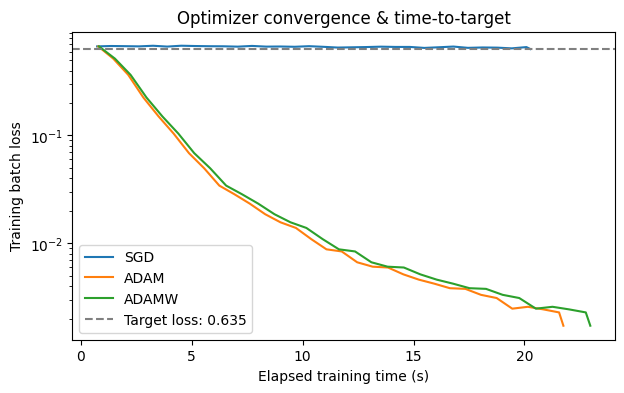

In [50]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
for name, values in history.items():
    ax.plot(values["time"],values["loss"],label=name.upper())

ax.axhline(0.635,color="gray",linestyle="--",label="Target loss: 0.635")
ax.set_xlabel("Elapsed training time (s)")
ax.set_ylabel("Training batch loss")
ax.set_yscale("log")
ax.set_title("Optimizer convergence & time-to-target")
ax.legend()
plt.show()

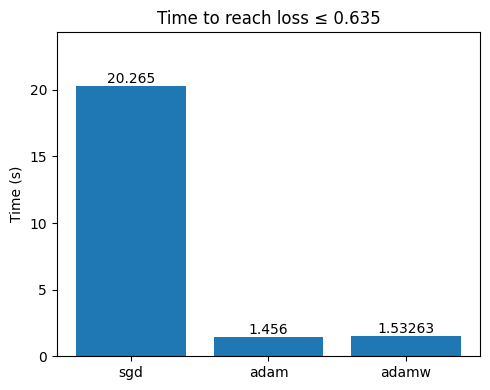

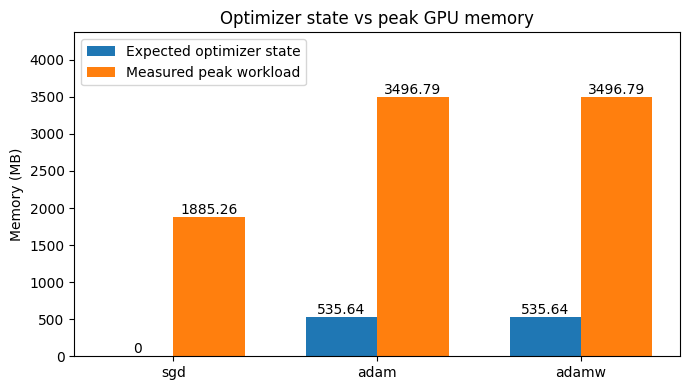

In [51]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(resultDf["Optimizer"],resultDf["Time to loss <= 0.635 (s)"].astype(float))
ax.set_title("Time to reach loss ≤ 0.635")
ax.set_ylabel("Time (s)")
ax.bar_label(bars)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

x = np.arange(len(resultDf))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4))
state_bars = ax.bar(x - width / 2,resultDf["Expected state bytes"].astype(float) / 1e6,width,label="Expected optimizer state")
peak_bars = ax.bar(x + width / 2,resultDf["Peak workload memory (MB)"].astype(float),width,label="Measured peak workload")
ax.set_xticks(x)
ax.set_xticklabels(resultDf["Optimizer"])
ax.set_title("Optimizer state vs peak GPU memory")
ax.set_ylabel("Memory (MB)")
ax.bar_label(state_bars)
ax.bar_label(peak_bars)
ax.margins(y=0.25)
ax.legend()

plt.tight_layout()
plt.show()

_Your C8 write-up: epoch time and convergence per optimizer, the state-byte ordering vs a memory figure, and the time-to-target comparison._

Comparing SGD, Adam, AdamW for 1 epoch (32 steps) over 1k reviews. The target_loss is set at 0.635. 

FYI: I selected 0.635 as target_loss based on hit-n-trial runs such that all three optimizers could reach it.

While each epoch times were about the same, Adam and AdamW converege way more faster than SGD. SGD reached the target_loss at 20.8 secs (end of the epoch), while Adam and AdamW reached it in ~1.5 secs.
AdamW was fastest in this run.

Zero buffers in Plain SGD (with no momentum). Adam and AdamW store two FP32 moment buffers, so 8 bytes/parameter. Their measured state exceeded the estimated by ~416 bytes.

The memory plot shows ordering: SGD < Adam = AdamW.
Peak workload memory follows the same.

## Short answers Q4 to Q6

**Q4 (3 pts).** Using your C8 figures, explain how optimizer memory changes from
SGD to Adam, in bytes per parameter.

My answer: optimizer_param_count = 66955010 (for DistilBERT). In C8, plain SGD (without momentum) uses 0 optimizer-state bytes. Adam & AdamW's two FP32 moment buffers add 8 bytes/parameter so optimizer_state_bytes = optimizer_param_count*8 = 535640080 bytes (or 535.6MB). This is expected but measured has an additional 416 bytes (probably some minor overhead).

**Q5 (2 pts).** From your C6 numbers, state the break-even rule in one sentence.

Compilation is beneficial only when N × (eager step time − compiled step time)
exceeds its extra startup overhead and for my run this happens from 6289 steps for default mode and 863 steps for reduce-overhead, so neither is feasible for our 20-step runs.


**Q6 (2 pts).** Name the GPU memory-timeline bands and say which grows fastest
with sequence length.

The bands are parameters, gradients, optimizer state, activations, and temporaries. One hidden-state tensor's shape is [Batch_size, Hidden_width, Sequence_length]. It takes BxLxH storage size. Doubling L will double this tensor’s memory. Transformers has multiple intermediate tensors across its layers (saved for backward propagation) hence activations grow fastest with sequence length. On other hand, just increasing input tokens cannot enlarge a linear layer’s weight matrix. Only the same weights are applied at more positions. Parameter, gradient, and optimizer-state sizes therefore remain unchanged. Temporary-memory growth depends on the implementation.

## Extra credit (+10)

- EC1 (+5): find a hidden CPU-GPU sync (an `.item()`/`.cpu()`/Python compare on a
  tensor in the loop), show its cost in the trace, remove it (L3 40 to 41).
- EC2 (+5): log recompiles across batch or sequence sizes, mark the varying
  dimension dynamic, and show the recompile count fall (L4 59 to 69).

## EC1

In [52]:
def ec1_step(model, batch, opt, read_loss):
    model.train()
    opt.zero_grad(set_to_none=True)
    loss = model(**batch).loss
    loss.backward()
    opt.step()
    loss = loss.detach()

    with torch.profiler.record_function("loss_readback"):
        if read_loss:
            return loss.item()
        return loss

if FULL_SCALE:
    from torch.profiler import profile, ProfilerActivity
    batch = {name: tensor.to(DEVICE) for name, tensor in _demo_batch.items()}

    results = []
    os.makedirs("traces", exist_ok=True)

    for read_loss, label in ((True, "before"), (False, "after")):
        torch.manual_seed(SEED)

        model = build_model(build_tiny_config()).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

        for _ in range(5):
            value = ec1_step(model, batch, opt, read_loss)

        torch.cuda.synchronize()
        start = time.perf_counter()

        for _ in range(50):
            value = ec1_step(model, batch, opt, read_loss)

        torch.cuda.synchronize()
        step_time = (time.perf_counter() - start) / 50

        if not read_loss:
            value = value.item()

        results.append({
            "Version": label,
            "Loss reading": (
                "Every step" if read_loss else "Once after loop"
            ),
            "Average step time (ms)": step_time * 1000,
        })

        with profile(
            activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        ) as p:
            for _ in range(3):
                value = ec1_step(model, batch, opt, read_loss)

            torch.cuda.synchronize()

        p.export_chrome_trace(f"traces/ec1_{label}.json")

        del model, opt, value

    ec1_results = pd.DataFrame(results)
    display(ec1_results)

,Version,Loss reading,Average step time (ms)
0,before,Every step,8.053981
1,after,Once after loop,7.845447


Before: Nested operations
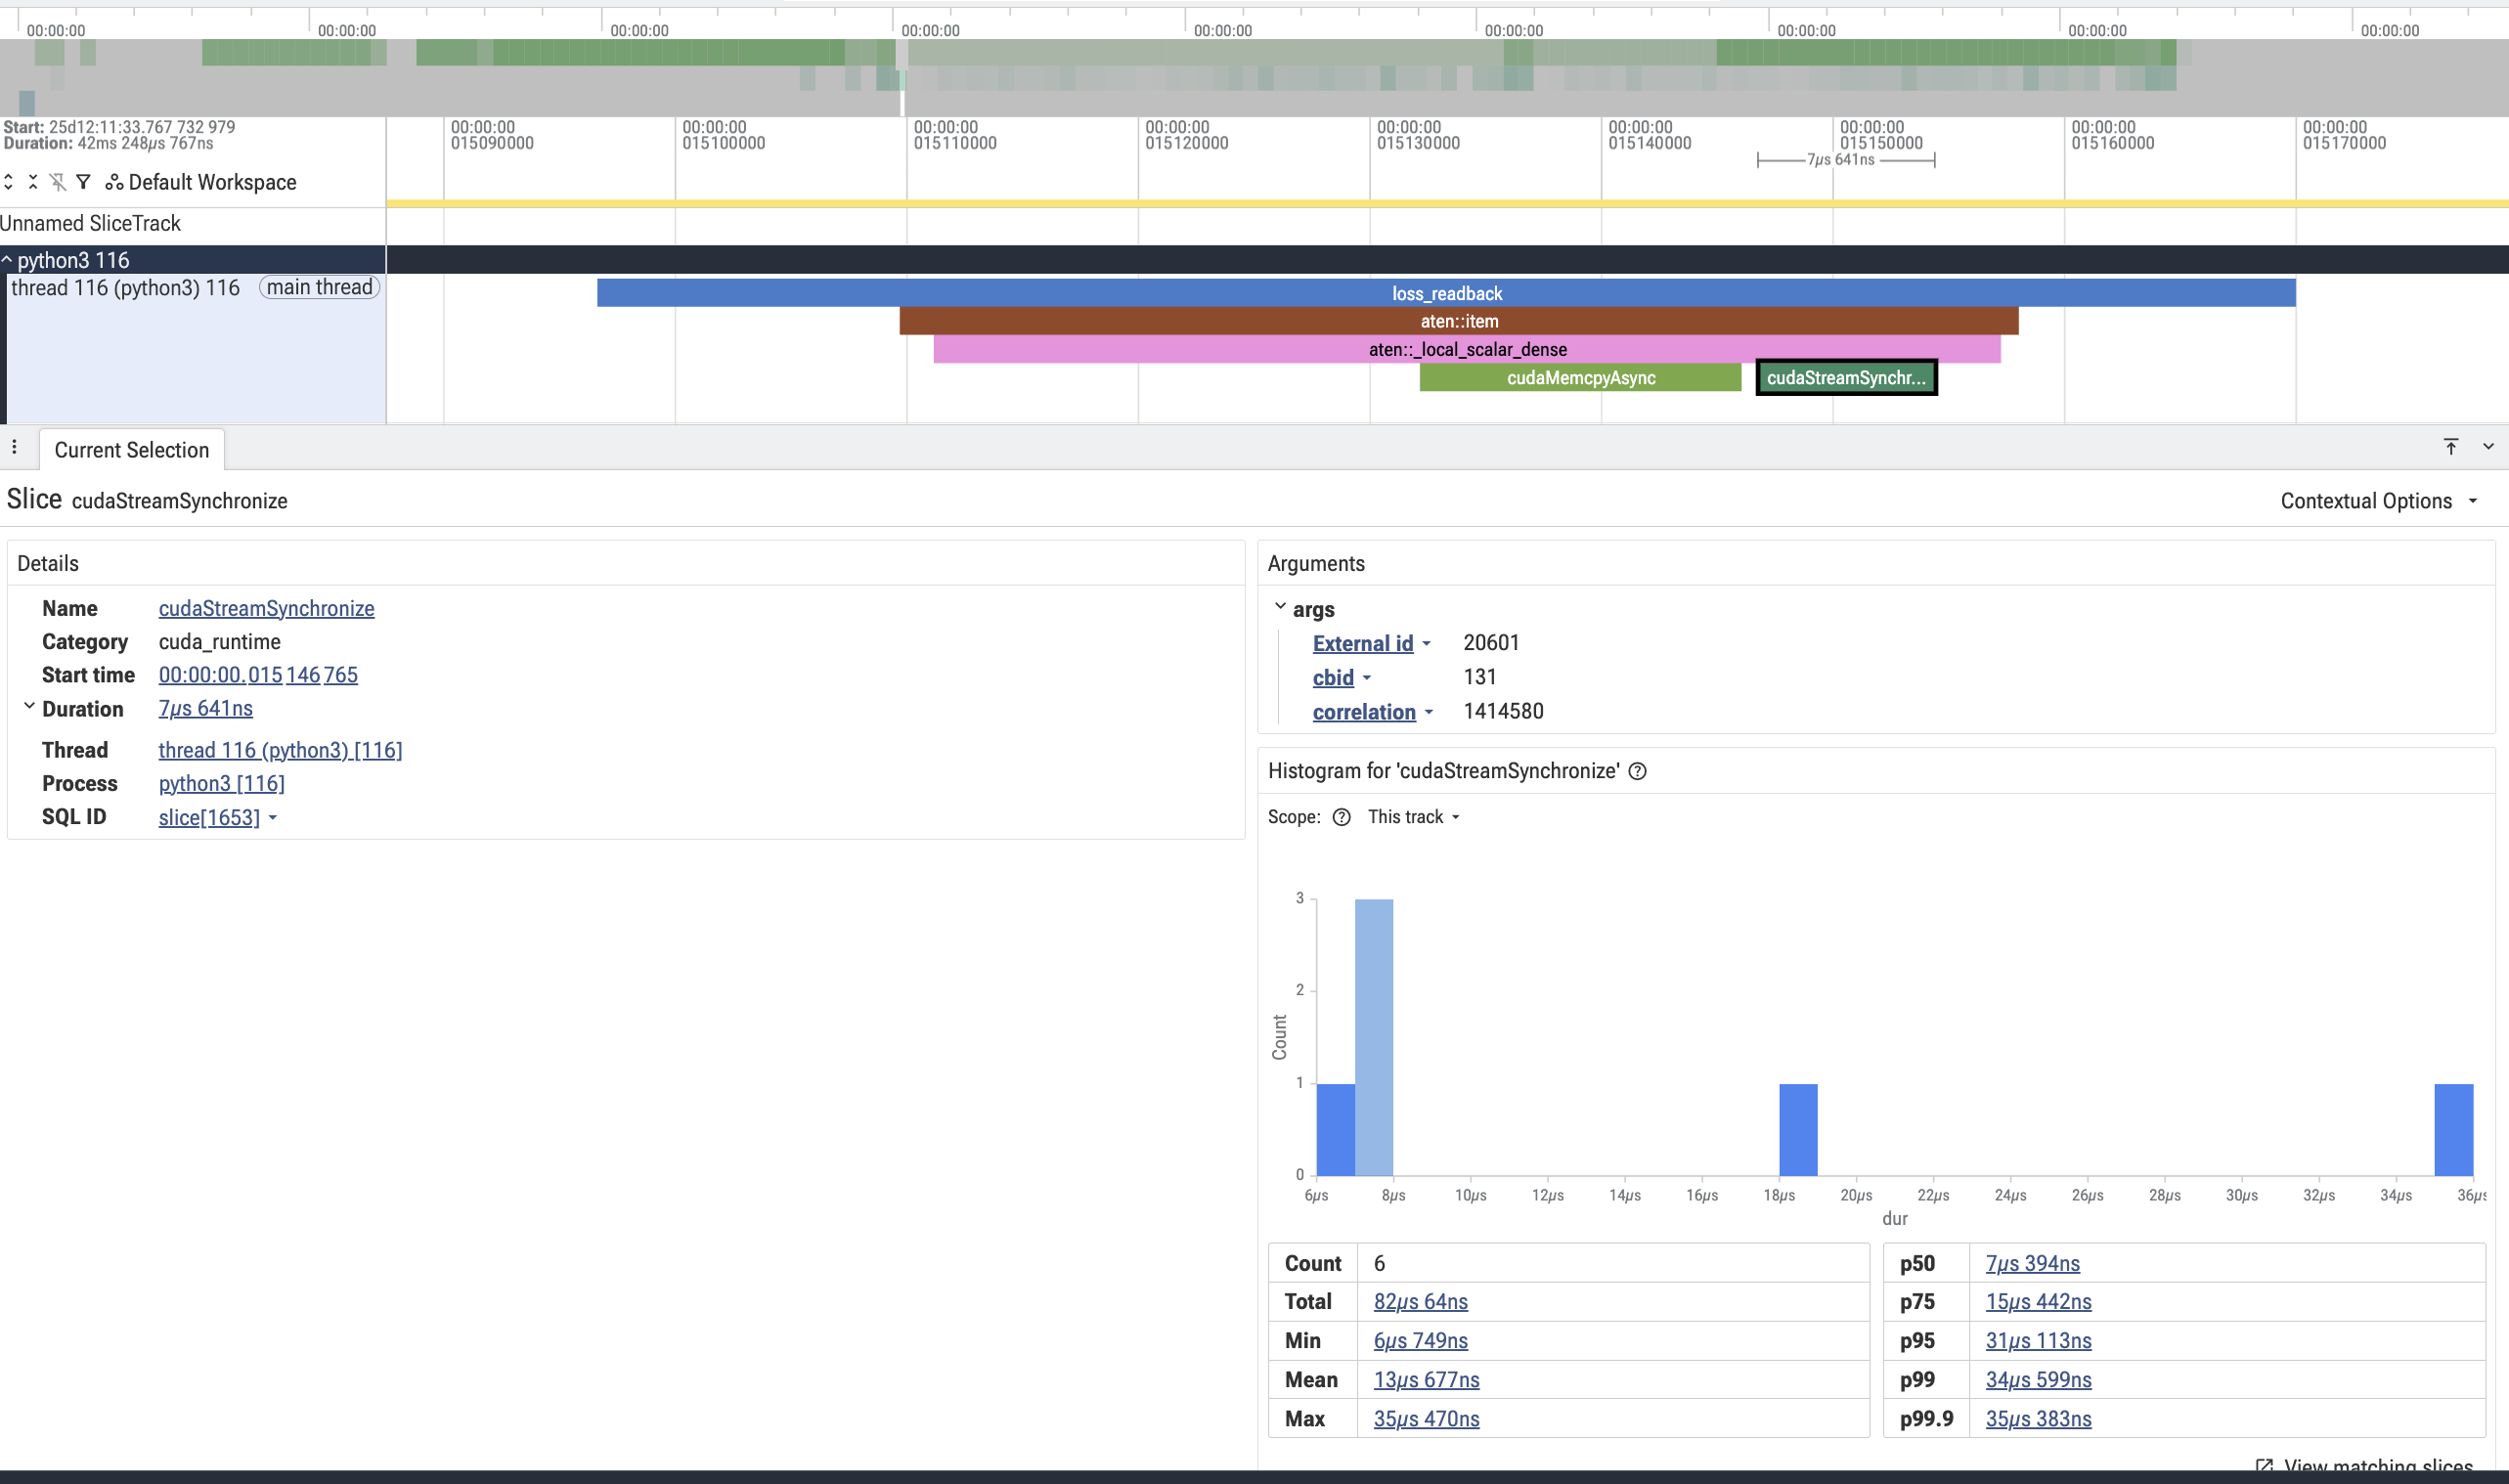

After: loss is a detached GPU tensor. The loss_readback region no longer has `.item(), scalar extraction, or the synchronization`.
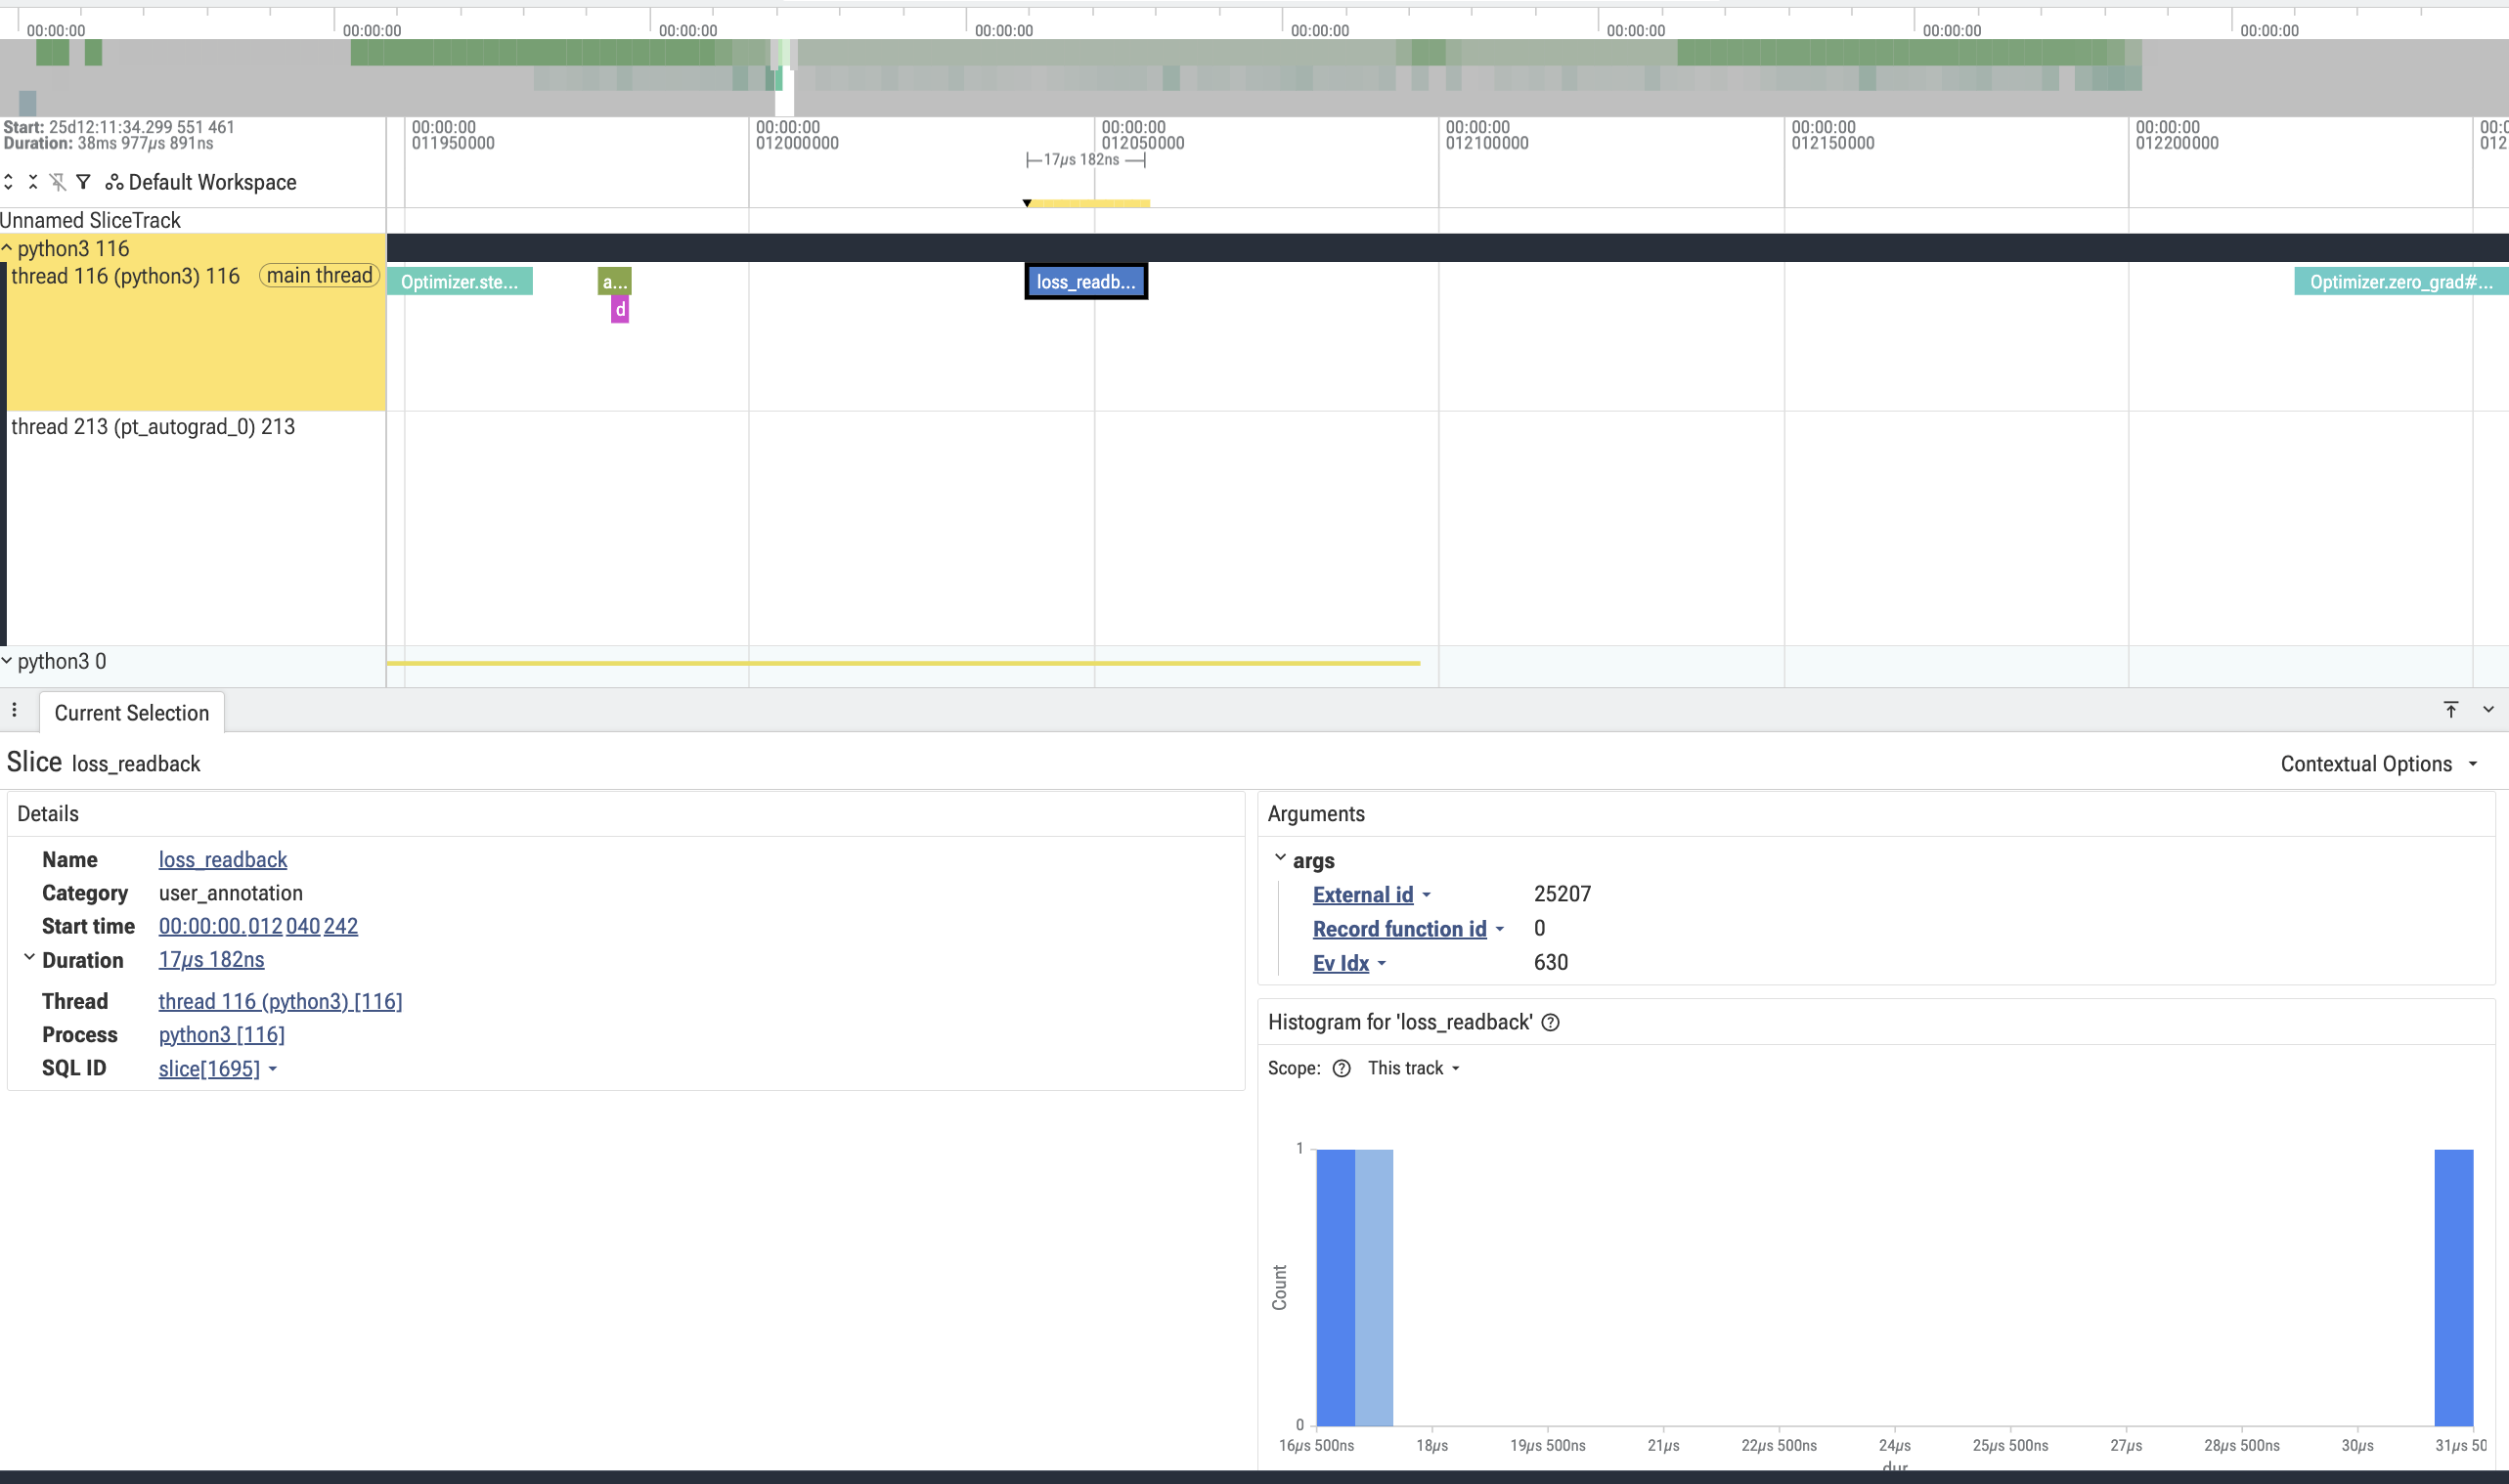

## EC 2

In [53]:
if FULL_SCALE:
    import torch._dynamo as dynamo

    model = build_model(build_tiny_config()).to(DEVICE)
    model.eval()

    def backend(graph, inputs):
        global count
        count += 1
        return graph.forward

    torch._logging.set_logs(recompiles=True)

    for dynamic in (False, True):
        dynamo.reset()
        count = 0
        torch.manual_seed(SEED)

        compiled = torch.compile(
            model,
            backend=backend,
            dynamic=dynamic,
            fullgraph=True,
        )

        print("\nDynamic shapes:", dynamic)

        with torch.no_grad():
            for length in (16, 24, 32, 48, 64):
                ids = torch.randint(
                    100, tokenizer.vocab_size,
                    (2, length), device=DEVICE,
                )
                mask = torch.ones_like(ids)

                compiled(input_ids=ids, attention_mask=mask)

                print("Length:", length, "Graphs:", count)

        print("Recompilations:", max(count - 1, 0))

    torch._logging.set_logs(recompiles=False)


Dynamic shapes: False


V1027 00:49:56.739000 116 torch/_dynamo/guards.py:4760] [0/1] [__recompiles] Recompiling function wrapper in /usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:933
V1027 00:49:56.739000 116 torch/_dynamo/guards.py:4760] [0/1] [__recompiles]     triggered by the following guard failure(s):
V1027 00:49:56.739000 116 torch/_dynamo/guards.py:4760] [0/1] [__recompiles]     - 0/0: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 16, actual 24


Length: 16 Graphs: 1


V1027 00:49:57.311000 116 torch/_dynamo/guards.py:4760] [0/2] [__recompiles] Recompiling function wrapper in /usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:933
V1027 00:49:57.311000 116 torch/_dynamo/guards.py:4760] [0/2] [__recompiles]     triggered by the following guard failure(s):
V1027 00:49:57.311000 116 torch/_dynamo/guards.py:4760] [0/2] [__recompiles]     - 0/1: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 24, actual 32
V1027 00:49:57.311000 116 torch/_dynamo/guards.py:4760] [0/2] [__recompiles]     - 0/0: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 16, actual 32


Length: 24 Graphs: 2


V1027 00:49:57.874000 116 torch/_dynamo/guards.py:4760] [0/3] [__recompiles] Recompiling function wrapper in /usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:933
V1027 00:49:57.874000 116 torch/_dynamo/guards.py:4760] [0/3] [__recompiles]     triggered by the following guard failure(s):
V1027 00:49:57.874000 116 torch/_dynamo/guards.py:4760] [0/3] [__recompiles]     - 0/2: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 32, actual 48
V1027 00:49:57.874000 116 torch/_dynamo/guards.py:4760] [0/3] [__recompiles]     - 0/1: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 24, actual 48
V1027 00:49:57.874000 116 torch/_dynamo/guards.py:4760] [0/3] [__recompiles]     - 0/0: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 16, actual 48


Length: 32 Graphs: 3


V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles] Recompiling function wrapper in /usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:933
V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles]     triggered by the following guard failure(s):
V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles]     - 0/3: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 48, actual 64
V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles]     - 0/2: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 32, actual 64
V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles]     - 0/1: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 24, actual 64
V1027 00:49:58.436000 116 torch/_dynamo/guards.py:4760] [0/4] [__recompiles]     - 0/0: tensor 'kwargs['input_ids']' size mismatch at index 1. expected 16, actual 64


Length: 48 Graphs: 4
Length: 64 Graphs: 5
Recompilations: 4

Dynamic shapes: True
Length: 16 Graphs: 1
Length: 24 Graphs: 1
Length: 32 Graphs: 1
Length: 48 Graphs: 1
Length: 64 Graphs: 1
Recompilations: 0


Model: Tiny DistilBERT 

Batch size = 2  

Sequence lengths traversed = [16, 24, 32, 48, 64]

| Setting | Graph captures | Recompilations |
|---|---:|---:|
| dynamic=False | 5 | 4 |
| dynamic=True | 1 | 0 |

When dynamic=False, new L triggers separate graph capture. I saw warnings of failed size guard on dimension input_ids = 16 (“expected 16, actual 24”)

When dynamic=True, all five lengths are managed by single captured graph. So recompilations automatically vanish (4 to 0).

## Before you submit

- [ ] Environment summary at the top of the notebook is filled in (GPU model,
      CUDA/driver version, `torch`/`transformers` versions).
- [ ] C1-C7 have real numbers/plots/tables from your **GPU** run, not the
      `FULL_SCALE=False` demo fallbacks.
- [ ] C4's Perfetto screenshots (and HTA output, if you used it) are included
      for both `num_workers` settings.
- [ ] Q1-Q5 are answered in labeled markdown cells (already scaffolded above).
- [ ] The notebook restarts and runs top to bottom without manual
      intervention (`Kernel -> Restart & Run All`).
- [ ] If you used W&B, it ran in offline mode and your screenshots/links are
      included; nothing in this notebook depends on a live W&B connection.